# Divergent development patterns in Scots pine forests are linked to land-use history and stand origin

### Statistical analyses: R code and results

Stanisław Zięba, Piotr Budniak, Jan Banaś, Leszek Bujoczek

This notebook contains the R code of all statistical analyses reported in the article, together with the results of its execution on the full data set. It reproduces Tables 2–5, Figures 3–11 and the Supplementary Tables S1–S30. Figures 1 and 2 are maps prepared in GIS software and are not produced by this notebook.

The study compares stands dominated by Scots pine (*Pinus sylvestris* L.) on 12,187 sample plots of the fourth cycle (2020–2024) of the Polish National Forest Inventory (NFI). Four types of stand origin combine the land-use history with the mode of establishment of the current stand (Table 1 of the article):

| Code | Stand origin | Land type | Mode of stand establishment |
|---|---|---|---|
| A | Afforestation of post-agricultural land | post-agricultural | artificial |
| NS | Natural succession on post-agricultural land | post-agricultural | natural |
| AR | Artificial regeneration on land with continuous forest cover | forest | artificial |
| NR | Natural regeneration on land with continuous forest cover | forest | natural |

#### Contents

| Notebook section | Methods | Results | Tables | Figures | Supplementary tables |
|---|---|---|---|---|---|
| 0. Setup | 2.6 | | | | |
| 1. Data | 2.1, 2.2 | | 2 | | S1 |
| 2. Growing stock volume: GAMM | 2.4 | 3.1 | 3 | 3 | S2–S5 |
| 3. Artificial – natural difference and stand age (H2) | 2.4 | 3.1 | | 4 | S6–S8 |
| 4. Growing stock volume and number of trees within age classes | 2.3 | 3.2 | | 5a, 6 | S10–S12, S17–S20 |
| 5. Species composition | 2.3, 2.5 | 3.3 | 4 | 5, 7 | S21–S24, S28–S30 |
| 6. Species diversity | 2.3 | 3.4 | | 8 | S13–S16 |
| 7. Standing dead trees | 2.3, 2.4 | 3.5 | 5 | 9–11 | S9, S25–S27 |
| 8. Software | 2.6 | | | | |

## 0. Setup

Packages, global options and the random seed, followed by the helpers for figures and tables. The package versions are listed in Section 8.

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)                  # data handling and figures (ggplot2)
  library(mgcv)                       # smooth terms of the GAMM
  library(gamm4)                      # GAMM with a random intercept of the NFI cluster
  library(lme4)
  library(nlme)                       # linear mixed models with heterogeneous residual variance
  library(emmeans)                    # estimated marginal means, contrasts and joint tests
  library(MASS, exclude = "select")   # negative binomial regression (glm.nb)
  library(splines)                    # natural cubic spline of stand age
  library(sandwich)                   # cluster-robust covariance matrices
  library(lmtest)                     # coefficient tests with a robust covariance matrix
  library(car, exclude = "recode")    # generalized variance inflation factors
  library(vegan)                      # Hellinger transformation, PCA, RDA, envfit
  library(ggrepel)                    # labels in the PCA biplot
})
emm_options(lmer.df = "asymptotic")
options(width = 120, cli.num_colors = 1, crayon.enabled = FALSE,
        jupyter.display_mimetypes = c("text/plain", "text/html"),
        jupyter.plot_mimetypes = c("text/plain", "image/png"), repr.plot.res = 200,
        repr.matrix.max.rows = 200, repr.matrix.max.cols = 50)
set.seed(2026)           # one seed for the whole notebook (see "Data and reproducibility")

data_dir <- "data"       # folder with the input files (Section 1.1)
save_outputs <- TRUE     # TRUE: figures (PNG) and tables (CSV, JSON) are also written to output_dir
output_dir <- "output"
figure_dpi <- 300

In [2]:
# Colors, font and layout of the figures (as in the article)
ink <- "#0b0b0b"; ink2 <- "#52514e"; grid_color <- "#e1e0d9"; axis_color <- "#c3c2b7"
frame_color <- "#898781"; header_fill <- "#e9e8e2"
font_family <- "Liberation Sans"
origins <- c("A", "NS", "AR", "NR")
origin_colors <- c(A = "#e87ba4", NS = "#eda100", AR = "#2a78d6", NR = "#008300")
origin_labels <- c(A = "A – afforestation", NS = "NS – natural succession",
                   AR = "AR – artificial regeneration", NR = "NR – natural regeneration")
model_color <- "#6250d6"
age_class_labels <- c("I (1–20 years)", "II (21–40 years)", "III (41–60 years)",
                      "IV (61–80 years)", "V (81–100 years)")

theme_pub <- function(base_size = 8) {
  theme_minimal(base_size = base_size, base_family = font_family) +
    theme(text = element_text(colour = ink),
          axis.text = element_text(colour = ink2, size = rel(1)),
          axis.title = element_text(size = rel(1.05)),
          axis.title.y = element_text(margin = margin(r = 6)),
          axis.title.x = element_text(margin = margin(t = 6)),
          axis.ticks.x = element_line(colour = frame_color, linewidth = 0.4),
          axis.ticks.length.x = unit(1.2, "mm"),
          panel.border = element_rect(colour = frame_color, fill = NA, linewidth = 0.5),
          panel.grid.major.x = element_blank(), panel.grid.minor = element_blank(),
          panel.grid.major.y = element_line(colour = grid_color, linewidth = 0.3),
          # the outline in the fill color hides the gap between the two lines of the panel header
          strip.background = element_rect(fill = header_fill, colour = header_fill, linewidth = 0.5),
          strip.text = element_text(colour = ink, size = rel(1), margin = margin(2.5, 4, 2.5, 4)),
          legend.title = element_text(colour = ink, size = rel(1.05)),
          legend.text = element_text(colour = ink2, size = rel(1)),
          legend.key.size = unit(3.5, "mm"),
          panel.spacing = unit(5, "mm"),
          plot.background = element_rect(fill = "white", colour = NA),
          plot.margin = margin(4, 6, 4, 4))
}
# Five age classes in a 2 × 3 layout: the legend goes to the empty sixth field
legend_in_sixth_panel <- if (packageVersion("ggplot2") >= "3.5.0") {
  theme(legend.position = "inside", legend.position.inside = c(0.835, 0.24))
} else {
  theme(legend.position = c(0.835, 0.24))
}
# Panel header with two lines (plotmath): what is tested (bold) and the result of the test
two_line_header <- function(titles, results) {
  lapply(list(sprintf('bold("%s")', titles), unname(results)), function(w) lapply(w, function(e) c(parse(text = e))))
}
age_class_panels <- function(results) {           # results: named by age class ("1"–"5")
  header <- function(labels) {
    ac <- as.character(labels$age_class)
    two_line_header(age_class_labels[as.integer(ac)], results[ac])
  }
  axes <- if (packageVersion("ggplot2") >= "3.5.0") list(axes = "all_x") else list(scales = "free_x")
  do.call(facet_wrap, c(list(~ age_class, nrow = 2, labeller = header), axes))
}
plot_header <- function(title, result) {
  facet_wrap(vars(header = 1), labeller = function(labels) two_line_header(title, result))
}
# Result of a test as a plotmath expression, e.g. LMM: F = 15.9, p < 0.001
test_result <- function(model, statistic, value, p, age_class = NULL) {
  p_txt <- ifelse(p < 0.001, '" < 0.001"', sprintf('" = %.3f"', p))
  setNames(sprintf('"%s: "*%s*" = %.1f, "*italic(p)*%s', model, statistic, value, p_txt), age_class)
}
show_figure <- function(plot, width_mm, height_mm, file) {
  if (save_outputs) {
    dir.create(file.path(output_dir, "figures"), recursive = TRUE, showWarnings = FALSE)
    ragg::agg_png(file.path(output_dir, "figures", file), width = width_mm, height = height_mm,
                  units = "mm", res = figure_dpi)
    print(plot); invisible(dev.off())
  }
  options(repr.plot.width = width_mm / 25.4, repr.plot.height = height_mm / 25.4)
  print(plot)
}

In [3]:
# Numbers as text, as in the article: minus sign, fixed number of decimals, p < 0.001
fmt <- function(x, d = 2) ifelse(is.na(x), "", gsub("-", "−", formatC(round(x, d) + 0, format = "f", digits = d)))
fmt_p <- function(p) ifelse(is.na(p), "", ifelse(p < 0.001, "< 0.001", formatC(p, format = "f", digits = 3)))
fmt_p_article <- function(p) sub("< ", "<", fmt_p(p), fixed = TRUE)     # p-values in Tables 3–5
fmt_n <- function(x) formatC(x, format = "d", big.mark = ",")
fmt_ci <- function(lo, hi, d = 2) paste(fmt(lo, d), "to", fmt(hi, d))
class_label <- function(age_class) age_class_labels[as.integer(as.character(age_class))]

# Labels of model terms in the tables
term_labels <- c(
  "(Intercept)" = "Intercept",
  fertilitypoor = "Site fertility group: poor",
  fertilitymoderately_fertile = "Site fertility group: moderately fertile",
  fertilityfertile = "Site fertility group: fertile",
  establishmentartificial = "Mode of establishment: artificial",
  landpost_agricultural = "Land type: post-agricultural",
  "establishmentartificial:landpost_agricultural" = "Artificial establishment × post-agricultural land",
  pine_share = "Scots pine share (% of volume)",
  shannon = "Shannon index (H′)",
  establishment_o.L = "Artificial − natural establishment (mean difference)",
  "s(age)" = "s(stand age)",
  "s(age):establishment_oartificial" = "s(stand age): artificial − natural difference",
  origin = "Stand origin", age_class = "Age class", fertility = "Site fertility group",
  "origin:age_class" = "Stand origin × age class")
reference_note <- "Reference categories: very poor site fertility group, natural establishment, forest land."

# A table is a character matrix; special rows: "##title" – block title, "!!…" – header row inside the table
block <- function(title, k) c(paste0("##", title), rep("", k - 1))
inner_header <- function(...) { x <- c(...); x[1] <- paste0("!!", x[1]); x }
pad <- function(m, k) { m <- rbind(m); if (ncol(m) < k) m <- cbind(m, matrix("", nrow(m), k - ncol(m))); m }

html_text <- function(x) {
  x <- gsub("&", "&amp;", x, fixed = TRUE); x <- gsub("<", "&lt;", x, fixed = TRUE)
  x <- gsub(">", "&gt;", x, fixed = TRUE)
  gsub("\\*([^*]+)\\*", "<i>\\1</i>", x)                                   # *text* – italics
}
show_table <- function(tab) {
  k <- length(tab$columns)
  row_html <- function(r) {
    if (startsWith(r[1], "##"))
      return(sprintf('<tr><td colspan="%d"><b>%s</b></td></tr>', k, html_text(substring(r[1], 3))))
    tag <- if (startsWith(r[1], "!!")) c("<td><b>", "</b></td>") else c("<td>", "</td>")
    paste0("<tr>", paste0(tag[1], html_text(sub("^!!", "", r)), tag[2], collapse = ""), "</tr>")
  }
  html <- paste0("<p><b>", tab$number, ".</b> ", html_text(tab$title), "</p><table><thead><tr>",
                 paste0("<th>", html_text(tab$columns), "</th>", collapse = ""), "</tr></thead><tbody>",
                 paste(apply(tab$rows, 1, row_html), collapse = ""), "</tbody></table>",
                 if (nzchar(tab$note)) paste0("<p><small>", html_text(tab$note), "</small></p>") else "")
  m <- rbind(tab$columns, tab$rows); m[] <- sub("^(##|!!)", "", m)
  w <- apply(nchar(m), 2, max)
  plain <- c(paste0(tab$number, ". ", tab$title),
             apply(m, 1, function(r) paste(mapply(function(x, n) format(x, width = n), r, w), collapse = "  ")),
             tab$note)
  IRdisplay::publish_mimebundle(list("text/plain" = paste(plain, collapse = "\n"), "text/html" = html))
}
# All tables of the article and of the Supplementary material: displayed, kept in `tables_out`, saved as CSV
tables_out <- list()
add_table <- function(number, title, columns, rows, note = "") {
  rows <- rbind(rows); dimnames(rows) <- NULL
  stopifnot(ncol(rows) == length(columns), !anyNA(rows))
  tab <- list(number = number, title = title, columns = columns, rows = rows, note = note)
  tables_out[[number]] <<- tab
  if (save_outputs) {
    dir.create(file.path(output_dir, "tables"), recursive = TRUE, showWarnings = FALSE)
    m <- rbind(columns, rows); m[] <- sub("^(##|!!)", "", m)
    write.table(m, file.path(output_dir, "tables", paste0(sub(" ", "_", number), ".csv")), sep = ",",
                row.names = FALSE, col.names = FALSE, fileEncoding = "UTF-8")
  }
  show_table(tab)
}

## 1. Data

### 1.1 Input files

| File | One row per | Content |
|---|---|---|
| `plots.csv` | plot | Stands dominated by Scots pine up to 120 years old (12,187 plots): plot (`plot_id`) and NFI cluster (`cluster`) identifiers, stand origin (`origin`), age of the dominant species in years (`age`), growing stock volume in m³ ha⁻¹ (`gsv`) and Shannon index (`shannon`). |
| `site_types.csv` | plot | NFI forest site type code (`site_type`). |
| `species_groups.csv` | plot × species group | Number (`n_trees`) and volume (`volume`, m³ per plot) of the trees with DBH ≥ 7 cm, all canopy layers, in three species groups (`species_group`): `pine` – Scots pine, `pioneer` – pioneer species (silver birch, aspen, larch), `other` – other species. |
| `tree_counts.csv` | plot | Number of trees with DBH ≥ 7 cm, all canopy layers (`n_trees`), with cluster, stand origin and age. |
| `standing_dead_trees.csv` | plot | Number (`dead_n`) and volume (`dead_vol`, m³ per plot) of standing dead trees; plots without standing dead trees have empty values or no row. |
| `pca_plots.csv` | plot | Stands dominated by Scots pine of all ages for the ordination (12,620 plots): identifiers, stand origin, age, growing stock volume (`gsv`), deadwood volume (`deadwood`), severity of stand damage (`damage`) and Shannon index (`shannon`). |
| `trees.csv` | tree | Trees with DBH ≥ 7 cm of the fourth NFI cycle: plot (`plot_id`), species (`species`) and canopy layer (`layer`; 1 – upper layer). |

Stand origin (`origin`) is coded as A, NS, AR and NR (Table 1 of the article). In `trees.csv`, the ten most abundant species of the upper canopy layer on the ordination plots are given by genus (sessile and pedunculate oak pooled as *Quercus*), and all other species as `Other species`. The sample plot area is 400 m².

In [4]:
# First five rows of each input file; NFI plot and cluster identifiers are replaced with sequential numbers
input_files <- c("plots.csv", "site_types.csv", "species_groups.csv", "tree_counts.csv", "standing_dead_trees.csv",
                 "pca_plots.csv", "trees.csv")
for (f in input_files) {
  d <- read.csv(file.path(data_dir, f), nrows = 5)
  for (k in intersect(names(d), c("plot_id", "cluster"))) d[[k]] <- paste0("#", seq_len(nrow(d)))
  IRdisplay::display_markdown(sprintf("**`%s`**", f))
  IRdisplay::display(d |> mutate(across(where(is.double), \(x) round(x, 3))))
}

**`plots.csv`**

plot_id,cluster,origin,age,gsv,shannon
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>
#1,#1,AR,10,0.551,0.000
#2,#2,A,11,6.103,0.319
#3,#3,A,11,5.309,0.611
#4,#4,AR,15,6.153,0.289
#5,#5,AR,14,13.604,0.111


**`site_types.csv`**

plot_id,site_type
<chr>,<int>
#1,NA
#2,18
#3,18
#4,18
#5,18


**`species_groups.csv`**

plot_id,species_group,n_trees,volume
<chr>,<chr>,<int>,<dbl>
#1,pine,12,1.521
#2,pine,15,0.639
#3,pine,17,0.983
#4,pine,9,0.488
#5,pine,10,2.654


... (4 outputs left out)

**`pca_plots.csv`**

plot_id,cluster,origin,age,gsv,deadwood,damage,shannon
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>
#1,#1,AR,110,420.006,0.000,3,0.780
#2,#2,AR,60,273.676,2.536,3,0.077
#3,#3,AR,65,463.737,0.000,0,0.077
#4,#4,AR,65,567.971,0.000,0,0.112
#5,#5,AR,65,439.915,0.000,4,0.171


**`trees.csv`**

plot_id,species,layer
<chr>,<chr>,<int>
#1,Pinus,1
#2,Pinus,1
#3,Betula,1
#4,Pinus,1
#5,Pinus,1


The Shannon index in the plot files was calculated from the volume shares of all tree species with DBH ≥ 7 cm on the plot, regardless of the canopy layer, with the natural logarithm (Section 2.2 of the article):

$$H' = -\sum_{i=1}^{K} p_i \ln p_i, \qquad p_i = v_i / V,$$

where *K* is the number of species on the plot, *v<sub>i</sub>* the volume of species *i* and *V* the volume of all trees.

### 1.2 Analysis data sets

- `plots` – 12,187 plots with stands up to 120 years old (age classes I–VI): the growing stock volume GAMM, hypothesis H2 and the model of standing dead trees (Sections 2, 3 and 7.1);
- `plots_100` – 11,164 plots with stands up to 100 years old (age classes I–V): comparisons within age classes (Sections 4, 5.1, 6 and 7.2); the number of trees (`trees_n`) and the numbers of trees of the species groups (`group_counts`) come from the same plots;
- `pca_plots` – 12,619 plots with upper-layer trees in stands of all ages, and their 6,325 cluster × origin units (`units`): ordination (Section 5.2).

In [5]:
# Age classes: 1 = 1–20 years, 2 = 21–40 years, …, 6 = 101–120 years
age_class_of <- function(age) ifelse(age <= 20, 1, ceiling(age / 20))

# NFI forest site type codes combined into four site fertility groups (reference: very poor)
fertility_codes <- list(
  very_poor          = c(11, 12, 13, 14, 72, 73),
  poor               = c(22, 23, 24, 55, 56, 81, 82),
  moderately_fertile = c(32, 33, 34, 61, 62, 91),
  fertile            = c(42, 43, 44, 45, 46, 63, 64, 65, 66, 93, 94))
fertility_group <- function(site_type) {
  lookup <- setNames(rep(names(fertility_codes), lengths(fertility_codes)), unlist(fertility_codes))
  factor(unname(lookup[as.character(site_type)]), levels = names(fertility_codes))
}

In [6]:
# Share of Scots pine in the growing stock volume of the plot (%), from the volumes of the three species groups
pine_share <- read.csv(file.path(data_dir, "species_groups.csv")) |>
  dplyr::select(plot_id, species_group, volume) |>
  pivot_wider(names_from = species_group, values_from = volume, values_fill = 0) |>
  transmute(plot_id, pine_share = pine / (pine + other + pioneer) * 100)

# Standing dead trees on the plot: number and volume (m³); no record = no standing dead trees
dead_trees <- read.csv(file.path(data_dir, "standing_dead_trees.csv")) |>
  transmute(plot_id, dead_n = coalesce(dead_n, 0L), dead_vol = coalesce(dead_vol, 0))

site_types <- read.csv(file.path(data_dir, "site_types.csv"))

# Plots with stands up to 120 years old
plots <- read.csv(file.path(data_dir, "plots.csv")) |>
  mutate(origin = factor(origin, levels = origins),
         establishment = factor(ifelse(origin %in% c("A", "AR"), "artificial", "natural"),
                                levels = c("natural", "artificial")),
         land = factor(ifelse(origin %in% c("AR", "NR"), "forest", "post_agricultural"),
                       levels = c("forest", "post_agricultural"))) |>
  inner_join(pine_share, by = "plot_id") |>
  inner_join(site_types, by = "plot_id") |>
  left_join(dead_trees, by = "plot_id") |>
  mutate(fertility = fertility_group(site_type), cluster = factor(cluster),
         dead_n = coalesce(dead_n, 0), dead_vol = coalesce(dead_vol, 0))

# Plots with stands up to 100 years old (age classes I–V): comparisons within age classes
plots_100 <- plots |> filter(age < 101) |> mutate(age_class = factor(age_class_of(age)))

# Number of trees with DBH ≥ 7 cm on the plot (all canopy layers), the same plots
trees_n <- read.csv(file.path(data_dir, "tree_counts.csv")) |>
  filter(plot_id %in% plots_100$plot_id) |>
  transmute(plot_id, cluster = factor(cluster), origin = factor(origin, levels = origins),
            age, age_class = factor(age_class_of(age)), n_trees)

# Numbers of trees with DBH ≥ 7 cm of the three species groups on the plot (all canopy layers), the same plots
group_counts <- read.csv(file.path(data_dir, "species_groups.csv")) |>
  dplyr::select(plot_id, species_group, n_trees) |>
  pivot_wider(names_from = species_group, values_from = n_trees, values_fill = 0) |>
  transmute(plot_id, pine, pioneer, other) |>
  inner_join(plots_100 |> dplyr::select(plot_id, cluster, origin, age_class), by = "plot_id") |>
  mutate(total = pine + pioneer + other)

stopifnot(!anyNA(plots$fertility), !anyNA(plots$origin), !anyNA(trees_n$origin),
          nrow(group_counts) == nrow(plots_100), all(group_counts$total > 0))
c(plots = nrow(plots), plots_100 = nrow(plots_100), trees_n = nrow(trees_n), group_counts = nrow(group_counts),
  clusters = n_distinct(plots$cluster), clusters_100 = n_distinct(plots_100$cluster))

plots    plots_100      trees_n group_counts     clusters clusters_100 
       12187        11164        11164        11164         5649         5409

In [7]:
# Ordination: plots of all ages and the species composition of their upper canopy layer (layer 1)
pca_file <- read.csv(file.path(data_dir, "pca_plots.csv")) |> mutate(origin = factor(origin, levels = origins))
upper_trees <- read.csv(file.path(data_dir, "trees.csv")) |> filter(layer == 1) |>
  inner_join(pca_file |> dplyr::select(plot_id), by = "plot_id")
# The ten most abundant species (genus names) followed by the pooled other species
species <- c(upper_trees |> filter(species != "Other species") |> count(species, sort = TRUE) |> pull(species),
             "Other species")
stopifnot(length(species) == 11)
composition <- upper_trees |> count(plot_id, species) |>
  pivot_wider(names_from = species, values_from = n, values_fill = 0)
pca_plots <- pca_file |> inner_join(composition, by = "plot_id") |>
  dplyr::select(plot_id, cluster, origin, age, gsv, deadwood, damage, shannon, all_of(species))

# Hellinger transformation: square root of the species shares in the number of upper-layer trees on the plot
H <- decostand(as.matrix(pca_plots[, species]), method = "hellinger")
# Units of RDA and PERMDISP: mean Hellinger profile of the plots of one origin in one NFI cluster
units <- bind_cols(pca_plots |> dplyr::select(cluster, origin, age), as_tibble(H)) |>
  group_by(cluster, origin) |> summarise(across(everything(), mean), .groups = "drop")
H_units <- as.matrix(units[, species])
c(upper_layer_trees = nrow(upper_trees), plots = nrow(H), cluster_origin_units = nrow(units))

upper_layer_trees                plots cluster_origin_units 
              346693                12619                 6325

### 1.3 Samples and data preview

In [8]:
table2 <- plots |> count(origin, age_class = age_class_of(age)) |>
  pivot_wider(names_from = age_class, values_from = n, values_fill = 0) |> arrange(origin)
add_table("Table 2", "Number of sample plots analyzed by stand origin and age class.",
          c("Origin", age_class_labels, "VI (101–120 years)"),
          cbind(as.character(table2$origin), apply(as.matrix(table2[, as.character(1:6)]), 2, fmt_n)),
          note = paste("Comparisons within age classes include classes I–V; the models of growing stock volume and of",
                       "standing dead trees include classes I–VI."))

Origin,I (1–20 years),II (21–40 years),III (41–60 years),IV (61–80 years),V (81–100 years),VI (101–120 years)
A,94,221,273,272,68,10
NS,138,207,35,43,13,4
AR,534,"1,145","2,240","3,020","2,325",936
NR,22,100,73,201,140,73


In [9]:
count_plots <- function(d, label) {
  n <- table(factor(d$origin, levels = origins))
  c(label, fmt_n(as.integer(n)), fmt_n(nrow(d)), fmt_n(n_distinct(d$cluster)))
}
add_table("Table S1", "Samples used in the analyses: numbers of plots by stand origin.",
          c("Analysis", origins, "Total", "Clusters"),
          rbind(count_plots(plots, "Growing stock volume, hypothesis H2 and standing dead trees: models (stands up to 120 years old)"),
                count_plots(plots_100, "Comparisons within age classes (stands up to 100 years old)"),
                count_plots(trees_n, "Number of trees within age classes"),
                count_plots(pca_plots, "Species composition: PCA and envfit (stands of all ages)"),
                count_plots(units, "Species composition: RDA and PERMDISP (cluster × origin units)")),
          note = paste("A – afforestation of post-agricultural land; NS – natural succession on post-agricultural land;",
                       "AR – artificial regeneration and NR – natural regeneration on land with continuous forest cover.",
                       "For RDA and PERMDISP the numbers are cluster × origin units (mean species profile of the plots",
                       "of one origin in one NFI cluster)."))

Analysis,A,NS,AR,NR,Total,Clusters
"Growing stock volume, hypothesis H2 and standing dead trees: models (stands up to 120 years old)",938,440,"10,200",609,"12,187","5,649"
Comparisons within age classes (stands up to 100 years old),928,436,"9,264",536,"11,164","5,409"
Number of trees within age classes,928,436,"9,264",536,"11,164","5,409"
Species composition: PCA and envfit (stands of all ages),939,442,"10,584",654,"12,619","5,753"
Species composition: RDA and PERMDISP (cluster × origin units),630,373,"4,855",467,"6,325","5,753"


In [10]:
# First five rows of the analysis data sets; NFI plot and cluster identifiers are replaced with sequential numbers
preview <- function(d, n = 5) {
  d <- as.data.frame(head(d, n)) |> mutate(across(where(is.double), \(x) round(x, 3)))
  for (k in intersect(names(d), c("plot_id", "cluster"))) d[[k]] <- paste0("#", seq_len(nrow(d)))
  d
}
IRdisplay::display(preview(plots_100))
IRdisplay::display(preview(trees_n))
IRdisplay::display(preview(group_counts))
preview(pca_plots)

,plot_id,cluster,origin,age,gsv,shannon,establishment,land,pine_share,site_type,dead_n,dead_vol,fertility,age_class
,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<fct>,<fct>,<dbl>,<int>,<dbl>,<dbl>,<fct>,<fct>
1,#1,#1,AR,10,0.551,0.000,artificial,forest,100.000,12,0,0,very_poor,1
2,#2,#2,A,11,6.103,0.319,artificial,post_agricultural,90.257,22,0,0,poor,1
3,#3,#3,A,11,5.309,0.611,artificial,post_agricultural,69.931,22,0,0,poor,1
4,#4,#4,AR,15,6.153,0.289,artificial,forest,91.574,12,0,0,very_poor,1
5,#5,#5,AR,14,13.604,0.111,artificial,forest,97.652,22,0,0,poor,1


,plot_id,cluster,origin,age,age_class,n_trees
,<chr>,<chr>,<fct>,<int>,<fct>,<int>
1,#1,#1,NR,50,3,19
2,#2,#2,NR,65,4,32
3,#3,#3,A,55,3,7
4,#4,#4,AR,80,4,25
5,#5,#5,AR,73,4,15


plot_id,pine,pioneer,other,cluster,origin,age_class,total
<chr>,<int>,<int>,<int>,<chr>,<fct>,<fct>,<int>
#1,12,0,0,#1,NS,3,12
#2,15,0,0,#2,NS,2,15
#3,17,0,0,#3,NS,3,17
#4,9,0,0,#4,NS,3,9
#5,10,0,9,#5,NR,3,19


,plot_id,cluster,origin,age,gsv,deadwood,damage,shannon,Pinus,Betula,Quercus,Picea,Larix,Fagus,Populus,Alnus,Carpinus,Abies,Other species
,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,#1,#1,AR,110,420.006,0.000,3,0.780,10,1,0,0,0,0,0,0,0,0,0
2,#2,#2,AR,60,273.676,2.536,3,0.077,16,0,0,0,0,0,0,0,0,0,0
3,#3,#3,AR,65,463.737,0.000,0,0.077,24,0,0,0,0,0,0,0,0,0,0
4,#4,#4,AR,65,567.971,0.000,0,0.112,29,0,0,0,0,0,0,0,0,0,0
5,#5,#5,AR,65,439.915,0.000,4,0.171,27,0,0,0,0,0,0,0,0,0,0


## 2. Growing stock volume: generalized additive mixed model

*Article: Sections 2.4 and 3.1, Table 3, Fig. 3, Tables S2–S5.*

Gaussian GAMM fitted with `gamm4` (REML) to the 12,187 plots:

$$\mathrm{E}(Y) = \beta_0 + s(\mathrm{age}) + \sum_{i=1}^{k} \beta_i X_i + b_{\mathrm{cluster}},$$

where *Y* is the growing stock volume, *s*(age) a smooth function of stand age (thin plate regression spline), *X<sub>i</sub>* the site fertility group (reference: very poor), land type (reference: forest land), mode of stand establishment (reference: natural), share of *Pinus sylvestris* in the growing stock volume (%) and Shannon index, and *b*<sub>cluster</sub> a random intercept of the NFI cluster (cluster as a factor, 5,649 clusters). Fixed effects are tested with *t*-tests and the smooth term with an approximate *F*-test. The fit is described by the adjusted *R*² of the fixed part and by the share of the cluster variance in the variance not explained by the fixed effects (intraclass correlation).

In [11]:
m_gsv <- gamm4(gsv ~ s(age) + fertility + establishment + land + pine_share + shannon,
               random = ~ (1 | cluster), data = plots, REML = TRUE)
s_gsv <- summary(m_gsv$gam)
vc_gsv <- as.data.frame(VarCorr(m_gsv$mer))
var_cluster <- vc_gsv$vcov[vc_gsv$grp == "cluster"]; var_resid <- vc_gsv$vcov[vc_gsv$grp == "Residual"]

coef_row <- function(term, label) {
  pt <- s_gsv$p.table
  c(label, fmt(pt[term, "Estimate"]), fmt(pt[term, "Std. Error"]), fmt(pt[term, "t value"]),
    fmt_p_article(pt[term, "Pr(>|t|)"]))
}
st <- s_gsv$s.table
add_table("Table 3",
          paste("Results of the generalized additive mixed model (GAMM) describing the effects of stand age, site",
                "fertility, mode of establishment, land type, share of *Pinus sylvestris* and Shannon index on the",
                "growing stock volume of pine stands."),
          c("Parametric coefficients", "Estimate β", "SE", "t/F", "p"),
          rbind(coef_row("(Intercept)", "Intercept"),
                block("Site fertility group", 5),
                coef_row("fertilitypoor", "poor"),
                coef_row("fertilitymoderately_fertile", "moderately fertile"),
                coef_row("fertilityfertile", "fertile"),
                block("Mode of establishment", 5), coef_row("establishmentartificial", "artificial"),
                block("Land type", 5), coef_row("landpost_agricultural", "post-agricultural land"),
                coef_row("pine_share", "Share of *Pinus sylvestris*"),
                coef_row("shannon", "Shannon index"),
                block("Smooth terms", 5),
                c("s(age)", paste("edf =", fmt(st["s(age)", "edf"])), "–", fmt(st["s(age)", "F"], 1),
                  fmt_p_article(st["s(age)", "p-value"])),
                c("cluster (random intercept)", paste("σ² =", fmt(var_cluster, 0)), "–", "–", "–")),
          note = sprintf(paste("Model: adjusted R² = %s (fixed part); −REML = %s; residual variance = %s; n = %s",
                               "(%s clusters). Reference categories: very poor sites, natural establishment, forest land."),
                         fmt(s_gsv$r.sq, 3), fmt_n(round(-logLik(m_gsv$mer)[1])), fmt_n(round(var_resid)),
                         fmt_n(nrow(plots)), fmt_n(n_distinct(plots$cluster))))

Table 3. Results of the generalized additive mixed model (GAMM) describing the effects of stand age, site fertility, mode of establishment, land type, share of *Pinus sylvestris* and Shannon index on the growing stock volume of pine stands.
Parametric coefficients      Estimate β  SE     t/F    p     
Intercept                    111.90      11.89  9.41   <0.001
Site fertility group                                         
poor                         61.07       2.43   25.10  <0.001
moderately fertile           97.81       3.05   32.07  <0.001
fertile                      118.99      5.36   22.18  <0.001
Mode of establishment                                        
artificial                   45.87       3.77   12.15  <0.001
Land type                                                    
post-agricultural land       0.78        3.42   0.23   0.818 
Share of *Pinus sylvestris*  1.25        0.11   11.18  <0.001
Shannon index                5.25        6.09   0.86   0.389 
Smooth terms                                                 
s(age)                       edf = 7.50  –      839.8  <0.001
cluster (random intercept)   σ² = 2653   –      –      –     
Model: adjusted R² = 0.475 (fixed part); −REML = 74,498; residual variance = 9,737; n = 12,187 (5,649 clusters). Reference categories: very poor sites, natural establishment, forest land.

In [12]:
# Parametric terms, smooth terms, random effect and fit of a GAMM fitted with gamm4
gamm_table <- function(m, data, d_beta = 2, d_var = 1, scale = NULL, exp_beta = FALSE) {
  s <- summary(m$gam); k <- if (exp_beta) 6 else 5
  pt <- as.data.frame(s$p.table) |> rownames_to_column("t")
  mult <- ifelse(pt$t %in% names(scale), scale[pt$t], 1)
  par <- cbind(term_labels[pt$t], fmt(pt$Estimate * mult, d_beta), fmt(pt$`Std. Error` * mult, d_beta),
               fmt(pt$`t value`), fmt_p(pt$`Pr(>|t|)`))
  if (exp_beta) par <- cbind(par, ifelse(pt$t == "(Intercept)", "", fmt(exp(pt$Estimate * mult), 3)))
  st <- as.data.frame(s$s.table) |> rownames_to_column("t")
  smooth <- cbind(term_labels[st$t], fmt(st$edf), fmt(st$Ref.df), fmt(st$F), fmt_p(st$`p-value`))
  vc <- as.data.frame(VarCorr(m$mer)); vt <- vc$vcov[vc$grp == "cluster"]; vr <- vc$vcov[vc$grp == "Residual"]
  fit <- rbind(c("Cluster random intercept: variance (SD)", paste0(fmt(vt, d_var), " (", fmt(sqrt(vt), d_var), ")")),
               c("Residual variance (SD)", paste0(fmt(vr, d_var), " (", fmt(sqrt(vr), d_var), ")")),
               c("Intraclass correlation of clusters", fmt(vt / (vt + vr), 3)),
               c("Adjusted R² (fixed part)", fmt(s$r.sq, 3)),
               c("Plots / clusters", paste(fmt_n(nrow(data)), "/", fmt_n(n_distinct(data$cluster)))))
  rbind(block("Parametric terms", k), pad(par, k),
        block("Smooth terms", k), pad(inner_header("Term", "edf", "Ref. df", "F", "p"), k), pad(smooth, k),
        block("Random effect and fit", k), pad(fit, k))
}
add_table("Table S2", "Generalized additive mixed model (GAMM) of growing stock volume (m³ ha⁻¹).",
          c("Term", "β", "SE", "t", "p"), gamm_table(m_gsv, plots),
          note = paste("Gaussian GAMM fitted with gamm4 (REML); NFI cluster as a random intercept. edf – effective",
                       "degrees of freedom; Ref. df – reference degrees of freedom. Adjusted R² refers to the fixed part",
                       "of the model.", reference_note))

Table S2. Generalized additive mixed model (GAMM) of growing stock volume (m³ ha⁻¹).
Term                                      β               SE       t       p      
Parametric terms                                                                  
Intercept                                 111.90          11.89    9.41    < 0.001
Site fertility group: poor                61.07           2.43     25.10   < 0.001
Site fertility group: moderately fertile  97.81           3.05     32.07   < 0.001
Site fertility group: fertile             118.99          5.36     22.18   < 0.001
Mode of establishment: artificial         45.87           3.77     12.15   < 0.001
Land type: post-agricultural              0.78            3.42     0.23    0.818  
Scots pine share (% of volume)            1.25            0.11     11.18   < 0.001
Shannon index (H′)                        5.25            6.09     0.86    0.389  
Smooth terms                                                                      
Term                                      edf             Ref. df  F       p      
s(stand age)                              7.50            7.50     839.82  < 0.001
Random effect and fit                                                             
Cluster random intercept: variance (SD)   2653.0 (51.5)                           
Residual variance (SD)                    9736.8 (98.7)                           
Intraclass correlation of clusters        0.214                                   
Adjusted R² (fixed part)                  0.475                                   
Plots / clusters                          12,187 / 5,649                          
Gaussian GAMM fitted with gamm4 (REML); NFI cluster as a random intercept. edf – effective degrees of freedom; Ref. df – reference degrees of freedom. Adjusted R² refers to the fixed part of the model. Reference categories: very poor site fertility group, natural establishment, forest land.

**Collinearity.** Generalized variance inflation factors for the linear counterpart of the model (stand age as a third-degree polynomial, without the random effect).

In [13]:
vif_tab <- vif(lm(gsv ~ poly(age, 3) + fertility + establishment + land + pine_share + shannon, data = plots))
vif_labels <- c("poly(age, 3)" = "Stand age (cubic polynomial)", fertility = "Site fertility group",
                establishment = "Mode of establishment (artificial vs. natural)",
                land = "Land type (post-agricultural vs. forest)",
                pine_share = "Scots pine share", shannon = "Shannon index (H′)")
add_table("Table S3",
          "Collinearity of predictors in the growing stock volume model: generalized variance inflation factors (GVIF).",
          c("Predictor", "GVIF", "df", "GVIF^(1/(2 df))"),
          cbind(vif_labels[rownames(vif_tab)], fmt(vif_tab[, "GVIF"]), fmt(vif_tab[, "Df"], 0), fmt(vif_tab[, 3])),
          note = paste("Computed for the linear counterpart of the model in Table S2 (stand age as a third-degree",
                       "polynomial, without the random effect)."))

Predictor,GVIF,df,GVIF^(1/(2 df))
Stand age (cubic polynomial),1.15,3,1.02
Site fertility group,1.40,3,1.06
Mode of establishment (artificial vs. natural),1.15,1,1.07
Land type (post-agricultural vs. forest),1.17,1,1.08
Scots pine share,4.19,1,2.05
Shannon index (H′),4.61,1,2.15


**Sensitivity to the scale of the model.** The spread of the residuals increases with the fitted value (Table S4), so the stability of the conclusions is checked with the same model for log-transformed growing stock volume (Table S5).

In [14]:
res_gsv <- residuals(m_gsv$gam); fit_gsv <- fitted(m_gsv$gam)
q_fit <- quantile(fit_gsv, 0:5 / 5); quintile <- cut(fit_gsv, q_fit, include.lowest = TRUE)
add_table("Table S4", "Spread of residuals of the growing stock volume model by quintiles of fitted values.",
          c("Quintile", "Fitted values (m³ ha⁻¹)", "Plots", "Residual SD (m³ ha⁻¹)"),
          cbind(1:5, fmt_ci(q_fit[-6], q_fit[-1], 0), fmt_n(as.vector(table(quintile))),
                fmt(as.vector(tapply(res_gsv, quintile, sd)), 1)),
          note = paste("The residual spread increases with the fitted value; the model was therefore also fitted for",
                       "log-transformed volume (Table S5)."))

m_log <- gamm4(log(gsv) ~ s(age) + fertility + establishment + land + pine_share + shannon,
               random = ~ (1 | cluster), data = plots, REML = TRUE)
add_table("Table S5", "GAMM of log-transformed growing stock volume (sensitivity analysis).",
          c("Term", "β", "SE", "t", "p", "exp(β)"),
          gamm_table(m_log, plots, d_beta = 4, d_var = 4, exp_beta = TRUE),
          note = paste("Same predictors and random effect as in Table S2. exp(β) is the multiplicative effect on",
                       "volume (e.g., 1.10 = 10% higher volume).", reference_note))

Quintile,Fitted values (m³ ha⁻¹),Plots,Residual SD (m³ ha⁻¹)
1,−178 to 255,"2,438",70.2
2,255 to 325,"2,437",98.2
3,325 to 361,"2,437",109.0
4,361 to 401,"2,437",120.7
5,401 to 479,"2,438",142.7


Table S5. GAMM of log-transformed growing stock volume (sensitivity analysis).
Term                                      β                SE       t        p        exp(β)
Parametric terms                                                                            
Intercept                                 3.9712           0.0537   73.95    < 0.001        
Site fertility group: poor                0.2547           0.0110   23.24    < 0.001  1.290 
Site fertility group: moderately fertile  0.3486           0.0137   25.38    < 0.001  1.417 
Site fertility group: fertile             0.3845           0.0242   15.92    < 0.001  1.469 
Mode of establishment: artificial         0.3181           0.0170   18.70    < 0.001  1.374 
Land type: post-agricultural              −0.0118          0.0154   −0.77    0.441    0.988 
Scots pine share (% of volume)            0.0111           0.0005   22.07    < 0.001  1.011 
Shannon index (H′)                        0.3427           0.0275   12.45    < 0.001  1.409 
Smooth terms                                                                                
Term                                      edf              Ref. df  F        p              
s(stand age)                              8.99             8.99     2451.27  < 0.001        
Random effect and fit                                                                       
Cluster random intercept: variance (SD)   0.0405 (0.2012)                                   
Residual variance (SD)                    0.2057 (0.4535)                                   
Intraclass correlation of clusters        0.164                                             
Adjusted R² (fixed part)                  0.713                                             
Plots / clusters                          12,187 / 5,649                                    
Same predictors and random effect as in Table S2. exp(β) is the multiplicative effect on volume (e.g., 1.10 = 10% higher volume). Reference categories: very poor site fertility group, natural establishment, forest land.

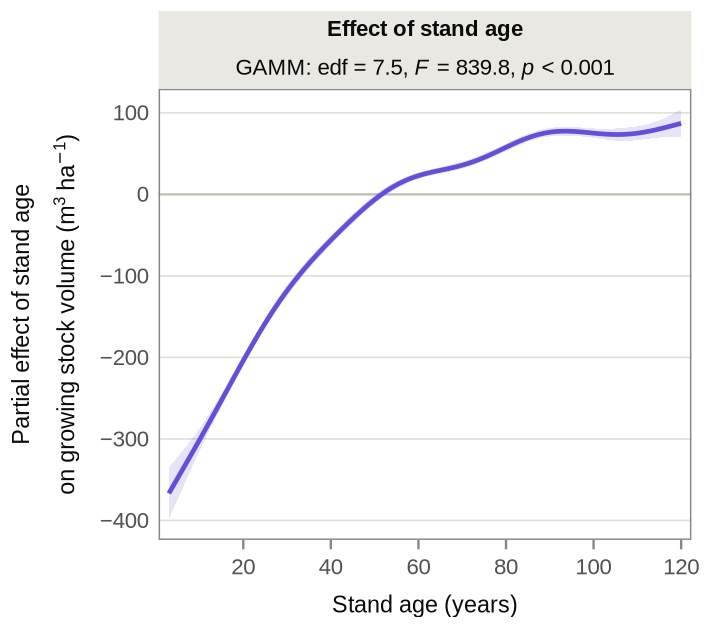

In [15]:
# Smooth effect of stand age with its 95% confidence interval
plot_smooth <- function(gam_obj, data, y_label, term = "s(age)") {
  grid <- data[rep(1, 200), ]
  grid$age <- seq(min(data$age), max(data$age), length.out = 200)
  pr <- predict(gam_obj, newdata = grid, type = "terms", terms = term, se.fit = TRUE)
  d <- tibble(age = grid$age, fit = pr$fit[, 1], se = pr$se.fit[, 1])
  ggplot(d, aes(age, fit)) +
    geom_hline(yintercept = 0, colour = axis_color, linewidth = 0.4) +
    geom_ribbon(aes(ymin = fit - 1.96 * se, ymax = fit + 1.96 * se), fill = model_color, alpha = 0.15) +
    geom_line(colour = model_color, linewidth = 0.8) +
    scale_x_continuous(breaks = seq(0, 120, 20), expand = expansion(mult = 0.02)) +
    scale_y_continuous(labels = scales::label_number(style_negative = "minus")) +
    labs(x = "Stand age (years)", y = y_label) +
    theme_pub()
}
smooth_result <- function(s_tab, term) {
  test_result("GAMM", sprintf('"edf = %.1f, "*italic(F)', s_tab[term, "edf"]), s_tab[term, "F"], s_tab[term, "p-value"])
}
fig3 <- plot_smooth(m_gsv$gam, plots,
                    expression(atop("Partial effect of stand age", "on growing stock volume (m"^3*" ha"^-1*")"))) +
  plot_header("Effect of stand age", smooth_result(s_gsv$s.table, "s(age)"))
show_figure(fig3, 90, 80, "figure_3.png")

## 3. Change of the artificial – natural difference with stand age (hypothesis H2)

*Article: Sections 2.4 and 3.1, Fig. 4, Tables S6–S8.*

The mode of establishment is coded as an ordered factor (natural < artificial). The term `s(age, by = establishment_o)` is then a smooth of the *difference* between artificially and naturally established stands, and its test shows whether the difference changes with age. This model is also compared by AIC (maximum likelihood fits) with the model with a constant difference (Section 2). The difference is estimated for ages 3–120 years with pointwise 95% confidence intervals.

The relative difference and the delay with which naturally established stands reach the growing stock volume that artificially established stands have at 30, 40 and 50 years are calculated for a typical stand: the most frequent site fertility group and land type, and the sample means of the share of pine and of the Shannon index. Only the relative difference depends on these values, because the model contains no interactions between the mode of establishment and the other variables.

In [16]:
plots$establishment_o <- ordered(plots$establishment, levels = c("natural", "artificial"))
m_h2 <- gamm4(gsv ~ establishment_o + land + s(age) + s(age, by = establishment_o) + fertility + pine_share + shannon,
              random = ~ (1 | cluster), data = plots, REML = TRUE)
aic_ml <- c(
  constant = AIC(gamm4(gsv ~ s(age) + fertility + establishment + land + pine_share + shannon,
                       random = ~ (1 | cluster), data = plots, REML = FALSE)$mer),
  age_dependent = AIC(gamm4(gsv ~ establishment_o + land + s(age) + s(age, by = establishment_o) + fertility +
                              pine_share + shannon, random = ~ (1 | cluster), data = plots, REML = FALSE)$mer))
add_table("Table S6",
          paste("GAMM testing whether the difference in growing stock volume (m³ ha⁻¹) between artificially and",
                "naturally established stands changes with stand age."),
          c("Term", "β", "SE", "t", "p"),
          rbind(gamm_table(m_h2, plots, scale = c(establishment_o.L = sqrt(2))),
                block("Model comparison (maximum likelihood fits)", 5),
                pad(rbind(c("AIC, constant difference (additive model)", fmt(aic_ml[["constant"]], 1)),
                          c("AIC, age-dependent difference", fmt(aic_ml[["age_dependent"]], 1)),
                          c("ΔAIC", fmt(aic_ml[["constant"]] - aic_ml[["age_dependent"]], 1))), 5)),
          note = paste("Mode of establishment coded as an ordered factor. The parametric term is the mean artificial −",
                       "natural difference (rescaled from the polynomial contrast); s(stand age): artificial − natural",
                       "difference is the centered difference smooth, and its test asks whether the difference changes",
                       "with age. Other terms as in Table S2.", reference_note))

Table S6. GAMM testing whether the difference in growing stock volume (m³ ha⁻¹) between artificially and naturally established stands changes with stand age.
Term                                                  β               SE       t       p      
Parametric terms                                                                              
Intercept                                             132.05          11.50    11.48   < 0.001
Artificial − natural establishment (mean difference)  51.84           3.97     13.05   < 0.001
Land type: post-agricultural                          −2.58           3.51     −0.74   0.462  
Site fertility group: poor                            61.22           2.43     25.18   < 0.001
Site fertility group: moderately fertile              97.87           3.05     32.12   < 0.001
Site fertility group: fertile                         119.75          5.37     22.32   < 0.001
Scots pine share (% of volume)                        1.24            0.11     11.17   < 0.001
Shannon index (H′)                                    5.60            6.09     0.92    0.357  
Smooth terms                                                                                  
Term                                                  edf             Ref. df  F       p      
s(stand age)                                          5.58            5.58     146.66  < 0.001
s(stand age): artificial − natural difference         5.30            5.30     5.50    < 0.001
Random effect and fit                                                                         
Cluster random intercept: variance (SD)               2649.0 (51.5)                           
Residual variance (SD)                                9717.6 (98.6)                           
Intraclass correlation of clusters                    0.214                                   
Adjusted R² (fixed part)                              0.476                                   
Plots / clusters                                      12,187 / 5,649                          
Model comparison (maximum likelihood fits)                                                    
AIC, constant difference (additive model)             149053.5                                
AIC, age-dependent difference                         149041.7                                
ΔAIC                                                  11.8                                    
Mode of establishment coded as an ordered factor. The parametric term is the mean artificial − natural difference (rescaled from the polynomial contrast); s(stand age): artificial − natural difference is the centered difference smooth, and its test asks whether the difference changes with age. Other terms as in Table S2. Reference categories: very poor site fertility group, natural establishment, forest land.

In [17]:
# Difference artificial − natural at given ages, from the linear predictor matrix of the model
difference_curve <- function(model, data, ages) {
  grid <- data[rep(1, length(ages)), ]; grid$age <- ages
  nd_art <- grid; nd_art$establishment_o <- factor("artificial", levels = levels(data$establishment_o), ordered = TRUE)
  nd_nat <- grid; nd_nat$establishment_o <- factor("natural", levels = levels(data$establishment_o), ordered = TRUE)
  D <- predict(model, nd_art, type = "lpmatrix") - predict(model, nd_nat, type = "lpmatrix")
  est <- drop(D %*% coef(model)); se <- sqrt(rowSums((D %*% vcov(model)) * D))
  tibble(age = ages, difference = est, lower = est - 1.96 * se, upper = est + 1.96 * se)
}
difference <- difference_curve(m_h2$gam, plots, 3:120)

# Typical stand: most frequent site fertility group and land type, mean share of pine and mean Shannon index
mode_of <- function(x) names(which.max(table(x)))
typical <- plots[1, ] |>
  mutate(fertility = factor(mode_of(plots$fertility), levels = levels(plots$fertility)),
         land = factor(mode_of(plots$land), levels = levels(plots$land)),
         pine_share = mean(plots$pine_share), shannon = mean(plots$shannon))
gsv_typical <- function(establishment, age) {
  d <- typical[rep(1, length(age)), ]; d$age <- age
  d$establishment_o <- factor(establishment, levels = levels(plots$establishment_o), ordered = TRUE)
  as.vector(predict(m_h2$gam, d))
}
IRdisplay::display(typical |> dplyr::select(fertility, land, pine_share, shannon))

h2_table <- difference |> filter(age %in% seq(10, 120, 10)) |>
  mutate(natural = gsv_typical("natural", age), artificial = gsv_typical("artificial", age),
         relative = 100 * (artificial - natural) / natural)
typical_txt <- sprintf(paste("%s site fertility group, land with continuous forest cover, Scots pine share",
                             "%s%% and Shannon index %s (the most frequent categories and sample means)"),
                       sub("_", " ", as.character(typical$fertility)), fmt(typical$pine_share, 1), fmt(typical$shannon, 3))
stopifnot(as.character(typical$land) == "forest")
add_table("Table S7",
          "Difference in growing stock volume between artificially and naturally established stands by stand age.",
          c("Stand age (years)", "Difference (m³ ha⁻¹)", "95% CI", "Natural (m³ ha⁻¹)", "Artificial (m³ ha⁻¹)",
            "Relative difference (%)"),
          with(h2_table, cbind(age, fmt(difference, 1), fmt_ci(lower, upper, 1), fmt(natural, 1), fmt(artificial, 1),
                               fmt(relative, 1))),
          note = paste0("From the model in Table S6. Difference = artificial − natural, with pointwise 95% confidence ",
                        "intervals. Predicted volumes and the relative difference refer to a typical stand: ", typical_txt,
                        ". The absolute difference does not depend on these values."))

# Age at which naturally established stands reach the volume of artificially established stands aged 30, 40 and 50 years
delay <- tibble(age_artificial = c(30, 40, 50), gsv_artificial = gsv_typical("artificial", age_artificial)) |>
  mutate(age_natural = map_dbl(gsv_artificial, \(v) uniroot(\(a) gsv_typical("natural", a) - v, c(1, 120))$root),
         delay = age_natural - age_artificial)
add_table("Table S8",
          "Age at which naturally established stands reach the growing stock volume of artificially established stands.",
          c("Age of artificially established stands (years)", "Volume of artificially established stands (m³ ha⁻¹)",
            "Age of naturally established stands with the same volume (years)", "Delay (years)"),
          with(delay, cbind(age_artificial, fmt(gsv_artificial, 1), fmt(age_natural, 1), fmt(delay, 1))),
          note = paste("From the model in Table S6, for the typical stand defined in Table S7. The delay does not depend",
                       "on the covariate values of the typical stand. The main text gives these delays as approximately",
                       "9, 14 and 25 years."))

,fertility,land,pine_share,shannon
,<fct>,<fct>,<dbl>,<dbl>
1,poor,forest,87.9978,0.2937047


Stand age (years),Difference (m³ ha⁻¹),95% CI,Natural (m³ ha⁻¹),Artificial (m³ ha⁻¹),Relative difference (%)
10,−9.6,−35.3 to 16.1,30.1,20.5,−31.8
20,19.8,6.0 to 33.5,102.5,122.3,19.3
30,43.1,30.0 to 56.1,168.0,211.1,25.6
40,57.6,42.9 to 72.3,218.1,275.7,26.4
50,63.9,48.9 to 78.9,261.5,325.4,24.4
60,58.5,44.8 to 72.2,295.2,353.7,19.8
70,50.3,37.8 to 62.9,316.1,366.5,15.9
80,54.6,41.5 to 67.7,333.9,388.4,16.4
90,62.6,48.4 to 76.8,345.0,407.6,18.1
100,59.0,42.8 to 75.2,347.5,406.5,17.0


Age of artificially established stands (years),Volume of artificially established stands (m³ ha⁻¹),Age of naturally established stands with the same volume (years),Delay (years)
30,211.1,38.5,8.5
40,275.7,53.7,13.7
50,325.4,75.1,25.1


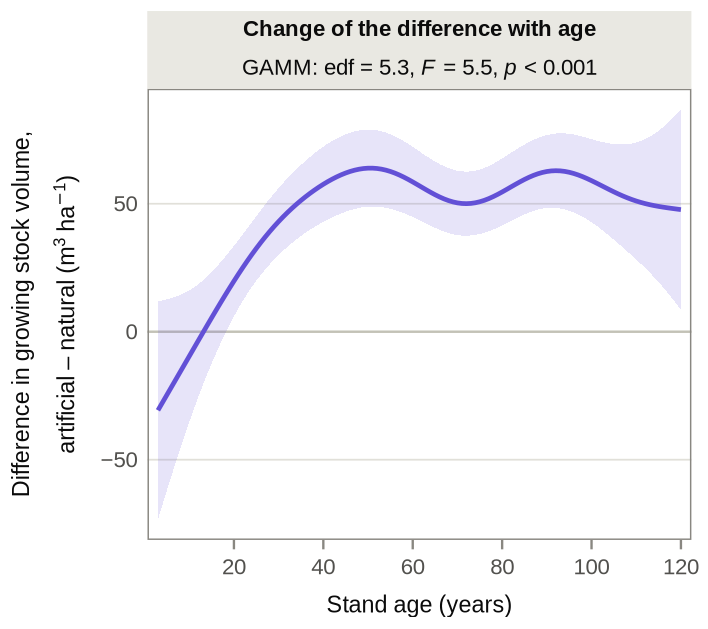

In [18]:
fig4 <- ggplot(difference, aes(age, difference)) +
  geom_hline(yintercept = 0, colour = axis_color, linewidth = 0.4) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = model_color, alpha = 0.15) +
  geom_line(colour = model_color, linewidth = 0.8) +
  scale_x_continuous(breaks = seq(0, 120, 20), expand = expansion(mult = 0.02)) +
  scale_y_continuous(labels = scales::label_number(style_negative = "minus")) +
  plot_header("Change of the difference with age",
              smooth_result(summary(m_h2$gam)$s.table, "s(age):establishment_oartificial")) +
  labs(x = "Stand age (years)",
       y = expression(atop("Difference in growing stock volume,", "artificial – natural (m"^3*" ha"^-1*")"))) +
  theme_pub()
show_figure(fig4, 90, 80, "figure_4.png")

## 4. Growing stock volume and number of trees within age classes

*Article: Sections 2.3 and 3.2, Figs. 5a and 6, Tables S10–S12 and S17–S20.*

Linear mixed models (`nlme::lme`, REML) with a stand origin × age class interaction, fitted to the plots up to 100 years old (age classes I–V, 11,164 plots, 5,409 clusters):

$$Y = \mu + \alpha_{\mathrm{origin}} + \beta_{\mathrm{class}} + (\alpha\beta)_{\mathrm{origin}\times\mathrm{class}} + \gamma_{\mathrm{fert}} + b_{\mathrm{cluster}} + \varepsilon,$$

- age class is a categorical variable, so the mean of each class is estimated without assuming a form of the change with age;
- *b*<sub>cluster</sub> – random intercept of the NFI cluster; *ε* – residual error with a variance estimated separately for each of the 20 origin × age class combinations (`varIdent`), supported by AIC against a variance that depends on age class only;
- *γ*<sub>fert</sub> – site fertility group, only in the growing stock volume model; the estimated marginal means are averaged over the four fertility groups with equal weights;
- simple effect of stand origin within each age class: joint *F*-test based on the full model (`emmeans::joint_tests`);
- pairwise comparisons of the estimated marginal means with the Holm correction (six comparisons per class) and homogeneous groups (α = 0.05; *a* – lowest mean);
- change with age within origin types: linear contrast of the marginal means across the five classes (coefficients −2, −1, 0, 1, 2) with the Holm correction for four origins; for the number of trees also the differences in this trend between pairs of origins (Holm correction for six pairs).

The Shannon index is analyzed with the same model in Section 6.

In [19]:
# optim: with a separate variance for each of the 20 cells, the default nlminb does not converge for volume
lme_control <- lmeControl(opt = "optim", maxIter = 500, msMaxIter = 500)

# Simple effect of origin within age classes, marginal means with 95% CI and homogeneous groups
compare_origins <- function(model) {
  emm <- emmeans(model, ~ origin | age_class)
  test <- joint_tests(model, by = "age_class") |> as.data.frame() |> filter(`model term` == "origin") |>
    transmute(age_class, F = round(F.ratio, 2), df1, df2, p = signif(p.value, 3))
  groups <- multcomp::cld(emm, adjust = "holm", Letters = letters, alpha = 0.05) |> as.data.frame() |>
    transmute(age_class, origin, group = trimws(.group))
  means <- confint(emm) |> as.data.frame() |> dplyr::select(age_class, origin, emmean, SE, lower.CL, upper.CL) |>
    left_join(groups, by = c("age_class", "origin"))
  list(test = test, means = means)
}
# AIC (REML) of the residual variance depending on age class only vs. on age class × origin
variance_aic <- function(m) {
  c(class = AIC(update(m, weights = varIdent(form = ~ 1 | age_class))), class_origin = AIC(m))
}
plot_means <- function(result, y_label) {
  m <- result$means |> mutate(age_class = as.integer(as.character(age_class)))
  ggplot(m, aes(origin, emmean)) +
    geom_linerange(aes(ymin = lower.CL, ymax = upper.CL, colour = origin), linewidth = 0.8) +
    geom_point(aes(fill = origin), shape = 21, size = 2.8, colour = "white", stroke = 0.8) +
    geom_text(aes(y = upper.CL, label = group), vjust = -0.6, size = 8 / .pt, colour = ink, family = font_family) +
    age_class_panels(test_result("LMM", "italic(F)", result$test$F, result$test$p, result$test$age_class)) +
    scale_colour_manual(values = origin_colors, labels = origin_labels, name = "Stand origin",
                        aesthetics = c("colour", "fill")) +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.12))) +
    labs(x = NULL, y = y_label) +
    theme_pub() + legend_in_sixth_panel
}
# Supplementary tables of an LMM: tests and variance components, marginal means, pairwise comparisons
lmm_tables <- function(numbers, name, unit, m, result, data, d, model_description) {
  jt <- as.data.frame(joint_tests(m))
  jk <- as.data.frame(joint_tests(m, by = "age_class")) |> filter(`model term` == "origin")
  sd_cluster <- as.numeric(VarCorr(m)["(Intercept)", "StdDev"])
  w <- coef(m$modelStruct$varStruct, unconstrained = FALSE, allCoef = TRUE)
  sd_res <- sapply(origins, \(o) m$sigma * w[paste0(1:5, "*", o)])
  aic <- variance_aic(m)
  add_table(numbers[1],
            sprintf("Linear mixed model of %s in age classes: tests of fixed effects and variance components.", name),
            c("Effect", "F", "df1", "df2", "p"),
            rbind(block("Fixed effects", 5),
                  cbind(term_labels[jt$`model term`], fmt(jt$F.ratio), fmt(jt$df1, 0), fmt(jt$df2, 0), fmt_p(jt$p.value)),
                  block("Simple effects of stand origin within age classes", 5),
                  cbind(class_label(jk$age_class), fmt(jk$F.ratio), fmt(jk$df1, 0), fmt(jk$df2, 0), fmt_p(jk$p.value)),
                  block(paste0("Variance components: SD", unit), 5),
                  pad(c("Cluster (random intercept)", fmt(sd_cluster, d)), 5),
                  inner_header("Residual SD, age class", origins),
                  cbind(age_class_labels, matrix(fmt(sd_res, d), 5)),
                  block("Residual variance structure", 5),
                  pad(inner_header("Residual variance", "AIC"), 5),
                  pad(rbind(c("Specific to age class", fmt(aic[["class"]], 1)),
                            c("Specific to age class × stand origin (used)", fmt(aic[["class_origin"]], 1))), 5)),
            note = paste(model_description, "Random intercept of NFI cluster; residual variance specific to each",
                         "age class × stand origin combination (nlme::lme, varIdent, REML), supported by AIC.",
                         "F tests from emmeans::joint_tests."))
  means <- result$means |> left_join(count(data, age_class, origin), by = c("age_class", "origin")) |>
    arrange(age_class, origin)
  add_table(numbers[2], sprintf("Estimated marginal means of %s by stand origin and age class.", name),
            c("Age class", "Stand origin", "Plots", paste0("Mean", unit), "SE", "95% CI", "Group"),
            with(means, cbind(class_label(age_class), as.character(origin), fmt_n(n), fmt(emmean, d), fmt(SE, d),
                              fmt_ci(lower.CL, upper.CL, d), group)),
            note = paste0("From the model in ", numbers[1], ". Means sharing a letter within an age class do not ",
                          "differ (pairwise comparisons with the Holm correction, α = 0.05, ", numbers[3], "); ",
                          "a – lowest mean."))
  pr <- as.data.frame(pairs(emmeans(m, ~ origin | age_class), adjust = "holm"))
  add_table(numbers[3], sprintf("Pairwise comparisons of stand origins within age classes: %s.", name),
            c("Age class", "Contrast", paste0("Difference", unit), "SE", "df", "t", "p (Holm)"),
            with(pr, cbind(class_label(age_class), gsub(" - ", " − ", as.character(contrast)), fmt(estimate, d),
                           fmt(SE, d), fmt(df, 0), fmt(t.ratio), fmt_p(p.value))),
            note = sprintf("From the model in %s; Holm correction for six comparisons within each age class.", numbers[1]))
  invisible(list(pairs = pr, aic = aic))
}

### 4.1 Growing stock volume

Model with site fertility group as a covariate; the figure is panel a of Fig. 5 (assembled with panel b in Section 5.1).

In [20]:
m_lmm_gsv <- lme(gsv ~ origin * age_class + fertility, random = ~ 1 | cluster,
                 weights = varIdent(form = ~ 1 | age_class * origin),
                 data = plots_100, method = "REML", control = lme_control)
r_gsv <- compare_origins(m_lmm_gsv)
t_gsv <- lmm_tables(c("Table S10", "Table S11", "Table S12"), "growing stock volume", " (m³ ha⁻¹)",
                    m_lmm_gsv, r_gsv, plots_100, 1,
                    paste("Growing stock volume ~ stand origin × age class + site fertility group. Marginal means are",
                          "averaged over site fertility groups with equal weights."))
fig5a <- plot_means(r_gsv, expression("Growing stock volume, adjusted for site fertility group (m"^3*" ha"^-1*")"))

Table S10. Linear mixed model of growing stock volume in age classes: tests of fixed effects and variance components.
Effect                                             F         df1    df2    p      
Fixed effects                                                                     
Stand origin                                       41.99     3      5733   < 0.001
Age class                                          394.29    4      5733   < 0.001
Site fertility group                               282.24    3      5733   < 0.001
Stand origin × age class                           10.13     12     5733   < 0.001
Simple effects of stand origin within age classes                                 
I (1–20 years)                                     12.75     3      5733   < 0.001
II (21–40 years)                                   34.27     3      5733   < 0.001
III (41–60 years)                                  16.93     3      5733   < 0.001
IV (61–80 years)                                   11.64     3      5733   < 0.001
V (81–100 years)                                   20.32     3      5733   < 0.001
Variance components: SD (m³ ha⁻¹)                                                 
Cluster (random intercept)                         41.3                           
Residual SD, age class                             A         NS     AR     NR     
I (1–20 years)                                     50.6      39.6   38.5   51.8   
II (21–40 years)                                   79.6      82.0   71.5   86.2   
III (41–60 years)                                  102.9     138.9  93.7   125.3  
IV (61–80 years)                                   126.3     180.1  105.6  131.8  
V (81–100 years)                                   127.2     108.0  116.9  117.5  
Residual variance structure                                                       
Residual variance                                  AIC                            
Specific to age class                              135283.4                       
Specific to age class × stand origin (used)        135221.2                       
Growing stock volume ~ stand origin × age class + site fertility group. Marginal means are averaged over site fertility groups with equal weights. Random intercept of NFI cluster; residual variance specific to each age class × stand origin combination (nlme::lme, varIdent, REML), supported by AIC. F tests from emmeans::joint_tests.

Age class,Stand origin,Plots,Mean (m³ ha⁻¹),SE,95% CI,Group
I (1–20 years),A,94,106.6,6.8,93.3 to 120.0,b
I (1–20 years),NS,138,59.3,5.0,49.5 to 69.1,a
I (1–20 years),AR,534,66.4,2.7,61.1 to 71.7,a
I (1–20 years),NR,22,80.4,13.7,53.5 to 107.3,ab
II (21–40 years),A,221,213.3,6.2,201.2 to 225.4,b
II (21–40 years),NS,207,154.3,6.5,141.4 to 167.1,a
II (21–40 years),AR,"1,145",214.1,2.8,208.7 to 219.5,b
II (21–40 years),NR,100,156.6,9.8,137.4 to 175.8,a
III (41–60 years),A,273,322.7,7.1,308.9 to 336.5,b
III (41–60 years),NS,35,211.1,24.5,163.0 to 259.2,a


Age class,Contrast,Difference (m³ ha⁻¹),SE,df,t,p (Holm)
I (1–20 years),A − NS,47.4,8.2,5733,5.80,< 0.001
I (1–20 years),A − AR,40.3,7.1,5733,5.67,< 0.001
I (1–20 years),A − NR,26.3,15.2,5733,1.73,0.336
I (1–20 years),NS − AR,−7.1,5.4,5733,−1.31,0.434
I (1–20 years),NS − NR,−21.1,14.5,5733,−1.46,0.434
I (1–20 years),AR − NR,−14.0,13.9,5733,−1.01,0.434
II (21–40 years),A − NS,59.0,8.8,5733,6.68,< 0.001
II (21–40 years),A − AR,−0.8,6.6,5733,−0.13,1.000
II (21–40 years),A − NR,56.7,11.5,5733,4.94,< 0.001
II (21–40 years),NS − AR,−59.9,6.9,5733,−8.70,< 0.001


### 4.2 Number of trees

In [21]:
m_lmm_n <- lme(n_trees ~ origin * age_class, random = ~ 1 | cluster,
               weights = varIdent(form = ~ 1 | age_class * origin),
               data = trees_n, method = "REML", control = lme_control)
r_n <- compare_origins(m_lmm_n)
t_n <- lmm_tables(c("Table S17", "Table S18", "Table S19"), "the number of trees (DBH ≥ 7 cm) per plot", "",
                  m_lmm_n, r_n, trees_n, 1, "Number of trees (DBH ≥ 7 cm) per 400 m² plot ~ stand origin × age class.")

Table S17. Linear mixed model of the number of trees (DBH ≥ 7 cm) per plot in age classes: tests of fixed effects and variance components.
Effect                                             F        df1   df2   p      
Fixed effects                                                                  
Stand origin                                       125.27   3     5736  < 0.001
Age class                                          216.02   4     5736  < 0.001
Stand origin × age class                           35.31    12    5736  < 0.001
Simple effects of stand origin within age classes                              
I (1–20 years)                                     94.45    3     5736  < 0.001
II (21–40 years)                                   144.61   3     5736  < 0.001
III (41–60 years)                                  10.23    3     5736  < 0.001
IV (61–80 years)                                   1.98     3     5736  0.114  
V (81–100 years)                                   3.66     3     5736  0.012  
Variance components: SD                                                        
Cluster (random intercept)                         6.1                         
Residual SD, age class                             A        NS    AR    NR     
I (1–20 years)                                     46.1     20.7  39.6  25.4   
II (21–40 years)                                   33.2     19.6  30.0  20.2   
III (41–60 years)                                  14.4     14.9  15.0  15.2   
IV (61–80 years)                                   9.5      9.0   8.9   11.9   
V (81–100 years)                                   6.8      4.6   6.6   9.4    
Residual variance structure                                                    
Residual variance                                  AIC                         
Specific to age class                              90917.4                     
Specific to age class × stand origin (used)        90748.6                     
Number of trees (DBH ≥ 7 cm) per 400 m² plot ~ stand origin × age class. Random intercept of NFI cluster; residual variance specific to each age class × stand origin combination (nlme::lme, varIdent, REML), supported by AIC. F tests from emmeans::joint_tests.

Age class,Stand origin,Plots,Mean,SE,95% CI,Group
I (1–20 years),A,94,82.7,4.8,73.2 to 92.1,c
I (1–20 years),NS,138,26.3,1.8,22.7 to 29.9,a
I (1–20 years),AR,534,64.2,1.7,60.8 to 67.6,b
I (1–20 years),NR,22,36.4,5.5,25.6 to 47.3,a
II (21–40 years),A,221,62.1,2.3,57.6 to 66.5,c
II (21–40 years),NS,207,31.9,1.4,29.1 to 34.7,a
II (21–40 years),AR,"1,145",65.4,0.9,63.6 to 67.1,c
II (21–40 years),NR,100,42.7,2.1,38.5 to 46.9,b
III (41–60 years),A,273,33.5,1.0,31.5 to 35.4,b
III (41–60 years),NS,35,25.1,2.7,19.8 to 30.4,a


Age class,Contrast,Difference,SE,df,t,p (Holm)
I (1–20 years),A − NS,56.4,5.1,5736,10.97,< 0.001
I (1–20 years),A − AR,18.5,5.1,5736,3.62,< 0.001
I (1–20 years),A − NR,46.2,7.3,5736,6.31,< 0.001
I (1–20 years),NS − AR,−37.9,2.5,5736,−15.00,< 0.001
I (1–20 years),NS − NR,−10.1,5.8,5736,−1.74,0.082
I (1–20 years),AR − NR,27.7,5.8,5736,4.78,< 0.001
II (21–40 years),A − NS,30.1,2.7,5736,11.21,< 0.001
II (21–40 years),A − AR,−3.3,2.5,5736,−1.35,0.178
II (21–40 years),A − NR,19.3,3.1,5736,6.21,< 0.001
II (21–40 years),NS − AR,−33.4,1.7,5736,−19.74,< 0.001


In [22]:
# Linear trend across age classes within origins, and differences in the trend between pairs of origins
trend_n_contrast <- contrast(emmeans(m_lmm_n, ~ age_class | origin), list(linear = c(-2, -1, 0, 1, 2)), name = "trend")
trend_n <- as.data.frame(trend_n_contrast) |> mutate(p_holm = p.adjust(p.value, "holm"))
trend_n_pairs <- as.data.frame(pairs(trend_n_contrast, by = "trend", adjust = "none")) |>
  mutate(p_holm = p.adjust(p.value, "holm"))
add_table("Table S20",
          "Linear trend of the number of trees (DBH ≥ 7 cm) per plot across age classes within stand origins.",
          c("Stand origin", "Estimate", "SE", "df", "t", "p", "p (Holm)"),
          rbind(block("Linear trend within stand origins", 7),
                with(trend_n, cbind(as.character(origin), fmt(estimate, 1), fmt(SE, 1), fmt(df, 0), fmt(t.ratio),
                                    fmt_p(p.value), fmt_p(p_holm))),
                block("Differences in linear trend between stand origins", 7),
                with(trend_n_pairs, cbind(gsub(" - ", " − ", as.character(contrast)), fmt(estimate, 1), fmt(SE, 1),
                                          fmt(df, 0), fmt(t.ratio), fmt_p(p.value), fmt_p(p_holm)))),
          note = paste("Linear polynomial contrast of the estimated marginal means over the five age classes",
                       "(coefficients −2, −1, 0, 1, 2), from the model in Table S17; negative values indicate a decrease",
                       "with age. Holm correction for four stand origins (trends) and for six pairs of stand origins",
                       "(differences in trend)."))

Table S20. Linear trend of the number of trees (DBH ≥ 7 cm) per plot across age classes within stand origins.
Stand origin                                       Estimate  SE    df    t       p        p (Holm)
Linear trend within stand origins                                                                 
A                                                  −157.3    10.1  5736  −15.51  < 0.001  < 0.001 
NS                                                 −19.3     5.8   5736  −3.30   < 0.001  0.002   
AR                                                 −121.5    3.6   5736  −33.68  < 0.001  < 0.001 
NR                                                 −36.2     11.5  5736  −3.16   0.002    0.002   
Differences in linear trend between stand origins                                                 
A − NS                                             −138.0    11.7  5736  −11.80  < 0.001  < 0.001 
A − AR                                             −35.8     10.8  5736  −3.33   < 0.001  0.002   
A − NR                                             −121.1    15.3  5736  −7.91   < 0.001  < 0.001 
NS − AR                                            102.2     6.9   5736  14.89   < 0.001  < 0.001 
NS − NR                                            16.9      12.9  5736  1.32    0.188    0.188   
AR − NR                                            −85.2     12.0  5736  −7.09   < 0.001  < 0.001 
Linear polynomial contrast of the estimated marginal means over the five age classes (coefficients −2, −1, 0, 1, 2), from the model in Table S17; negative values indicate a decrease with age. Holm correction for four stand origins (trends) and for six pairs of stand origins (differences in trend).

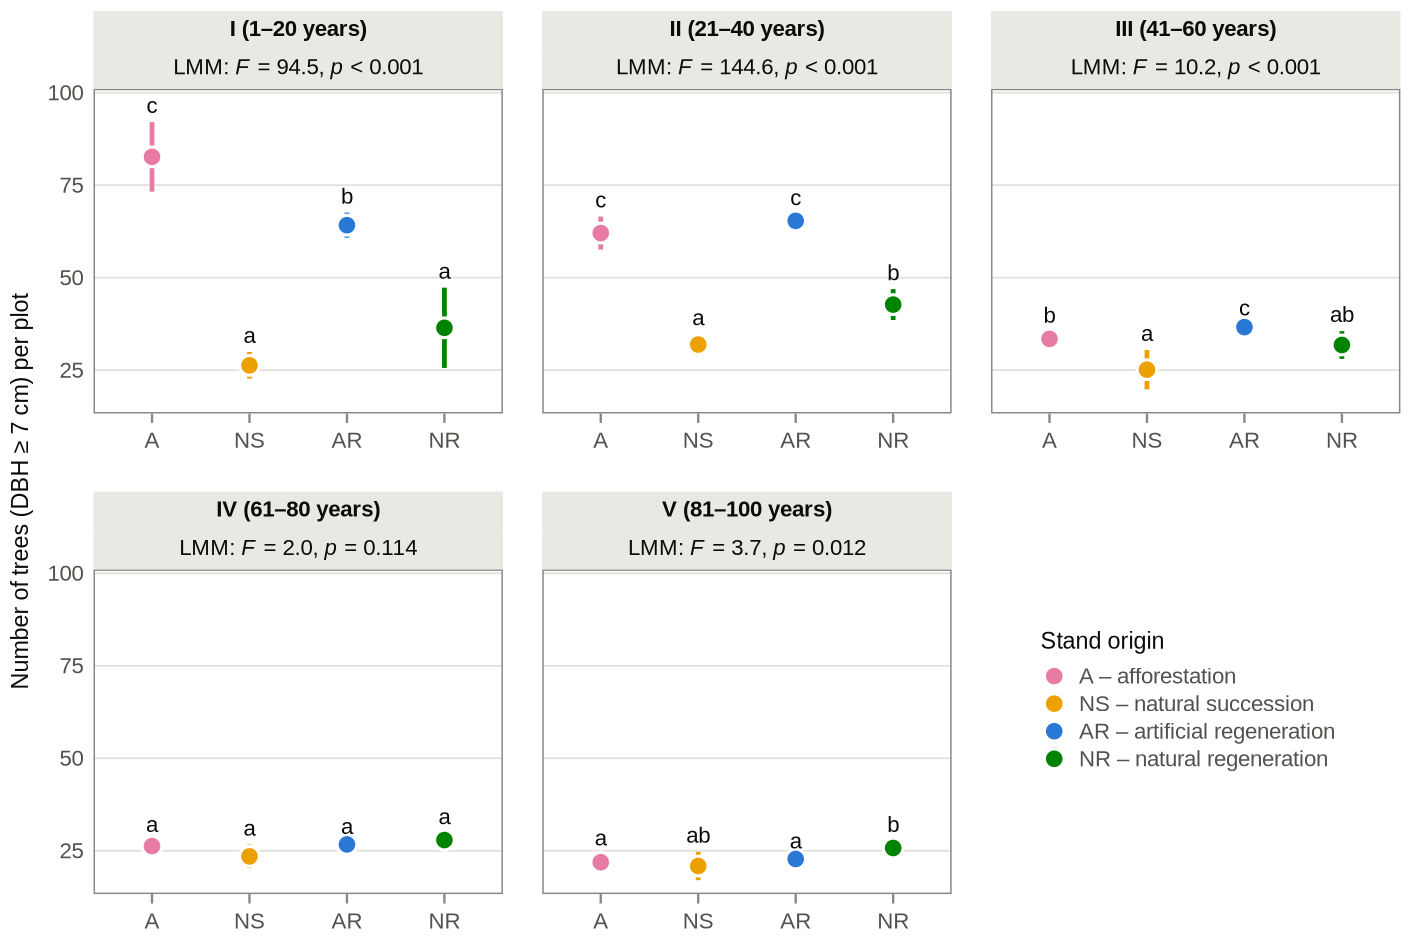

In [23]:
fig6 <- plot_means(r_n, "Number of trees (DBH ≥ 7 cm) per plot")
show_figure(fig6, 180, 120, "figure_6.png")

## 5. Species composition

*Article: Sections 2.3, 2.5 and 3.3, Table 4, Figs. 5 and 7, Tables S21–S24 and S28–S30.*

### 5.1 Shares of species groups within age classes

The shares of Scots pine, pioneer species (silver birch, aspen and larch) and other species in each origin × age class cell are the number of trees of the group divided by the number of all trees with DBH ≥ 7 cm (all canopy layers). Only the share of pine is tested, with a quasi-binomial GLM with a logit link:

$$\mathrm{logit}\big(\mathrm{E}(Y)\big) = \mu + \alpha_{\mathrm{origin}} + \beta_{\mathrm{class}} + (\alpha\beta)_{\mathrm{origin}\times\mathrm{class}},$$

fitted to the numbers of pine and other trees on the plots, with standard errors robust to the clustering of plots within NFI clusters (`sandwich::vcovCL`). The simple effect of origin within each age class is tested with a Wald χ² test, and the pairwise comparisons use the Holm correction. The model contains only the origin × age class cells, so its fitted shares equal the observed shares. The same GLM approach is used for standing dead trees in Section 7.2.

In [24]:
# GLM with origin × age class: cluster-robust Wald tests, homogeneous groups and pairwise ratios (Holm)
compare_origins_glm <- function(model) {
  V <- vcovCL(model, cluster = ~ cluster)
  emm <- emmeans(model, ~ origin | age_class, vcov. = V)
  test <- joint_tests(model, by = "age_class", vcov. = V) |> as.data.frame() |> filter(`model term` == "origin") |>
    transmute(age_class, chi2 = round(Chisq, 1), df = df1, p = signif(p.value, 3))
  groups <- multcomp::cld(emm, adjust = "holm", Letters = letters, alpha = 0.05) |> as.data.frame() |>
    transmute(age_class, origin, group = trimws(.group))
  list(test = test, groups = groups, model = model, V = V, emm = emm,
       pairs = as.data.frame(pairs(emm, type = "response", adjust = "holm")))
}
glm_tests <- function(r, title) {
  jt <- as.data.frame(joint_tests(r$model, vcov. = r$V))
  rbind(block(title, 4),
        cbind(term_labels[jt$`model term`], fmt(jt$Chisq, 1), fmt(jt$df1, 0), fmt_p(jt$p.value)),
        cbind(paste("Stand origin in age class", class_label(r$test$age_class)), fmt(r$test$chi2, 1),
              fmt(r$test$df, 0), fmt_p(r$test$p)))
}
glm_pairs <- function(r, title) {
  pr <- r$pairs; est <- intersect(c("ratio", "odds.ratio"), names(pr))
  rbind(block(title, 6),
        cbind(class_label(pr$age_class), as.character(pr$contrast), fmt(pr[[est]], 3), fmt(pr$SE, 3),
              fmt(pr$z.ratio), fmt_p(pr$p.value)))
}
glm_note <- "Wald tests with cluster-robust covariance matrix (NFI clusters; sandwich::vcovCL)."

In [25]:
species_group_colors <- c("Other species" = "#6250d6", "Pioneer species" = "#eb6834", "Scots pine" = "#1baf7a")
species_group_names <- c(other = "Other species", pioneer = "Pioneer species", pine = "Scots pine")
shares <- group_counts |>
  pivot_longer(c(pine, pioneer, other), names_to = "species_group", values_to = "n") |>
  group_by(age_class, origin, species_group) |> summarise(n = sum(n), .groups = "drop_last") |>
  mutate(share = n / sum(n)) |> ungroup() |>
  mutate(species_group = factor(species_group_names[species_group], levels = names(species_group_colors))) |>
  arrange(age_class, origin, match(species_group, c("Pioneer species", "Scots pine", "Other species")))

r_pine <- compare_origins_glm(glm(cbind(pine, total - pine) ~ origin * age_class, family = quasibinomial,
                                  data = group_counts))
composition_table <- shares |> dplyr::select(age_class, origin, species_group, share) |>
  pivot_wider(names_from = species_group, values_from = share) |>
  left_join(group_counts |> group_by(age_class, origin) |> summarise(plots = n(), trees = sum(total), .groups = "drop"),
            by = c("age_class", "origin")) |>
  left_join(r_pine$groups, by = c("age_class", "origin")) |> arrange(age_class, origin)
add_table("Table S28",
          "Species composition by stand origin and age class: shares of species groups in the number of trees.",
          c("Age class", "Stand origin", "Plots", "Trees", "Scots pine (%)", "Group", "Pioneer species (%)",
            "Other species (%)"),
          with(composition_table, cbind(class_label(age_class), as.character(origin), fmt_n(plots), fmt_n(trees),
                                        fmt(100 * `Scots pine`, 1), group, fmt(100 * `Pioneer species`, 1),
                                        fmt(100 * `Other species`, 1))),
          note = paste("Trees with DBH ≥ 7 cm in all canopy layers; pioneer species: silver birch (*Betula pendula*),",
                       "aspen (*Populus tremula*) and larch (*Larix* spp.);",
                       "share = number of trees of the group / number of all trees in the cell. Groups refer to the",
                       "share of Scots pine: shares sharing a letter within an age class do not differ (pairwise",
                       "comparisons with the Holm correction, α = 0.05, Table S30); a – lowest share."))
add_table("Table S29", "Tests of differences in the share of Scots pine between stand origins.",
          c("Effect", "χ²", "df", "p"), glm_tests(r_pine, "Share of Scots pine: quasi-binomial GLM"),
          note = paste("Model: cbind(Scots pine, other trees) ~ stand origin × age class with logit link, stands up",
                       "to 100 years old; fitted shares equal the shares in Table S28.", glm_note))
add_table("Table S30", "Pairwise comparisons of stand origins within age classes: share of Scots pine.",
          c("Age class", "Contrast", "Odds ratio", "SE", "z", "p (Holm)"),
          glm_pairs(r_pine, "Share of Scots pine"),
          note = paste("Odds ratios from the model in Table S29; Holm correction for six comparisons within each age",
                       "class.", glm_note))

Age class,Stand origin,Plots,Trees,Scots pine (%),Group,Pioneer species (%),Other species (%)
I (1–20 years),A,94,"7,761",91.0,ab,6.3,2.7
I (1–20 years),NS,138,"3,684",85.2,a,7.0,7.8
I (1–20 years),AR,534,"34,270",92.6,b,4.8,2.6
I (1–20 years),NR,22,781,83.2,ab,6.8,10.0
II (21–40 years),A,221,"13,729",85.6,a,8.9,5.6
II (21–40 years),NS,207,"6,594",82.3,a,11.1,6.5
II (21–40 years),AR,"1,145","74,829",89.7,b,5.3,5.0
II (21–40 years),NR,100,"4,300",78.7,a,14.5,6.8
III (41–60 years),A,273,"9,120",82.5,b,4.6,12.9
III (41–60 years),NS,35,841,77.6,ab,11.2,11.2


Table S29. Tests of differences in the share of Scots pine between stand origins.
Effect                                       χ²     df  p      
Share of Scots pine: quasi-binomial GLM                        
Stand origin                                 101.3  3   < 0.001
Age class                                    354.1  4   < 0.001
Stand origin × age class                     12.2   12  0.432  
Stand origin in age class I (1–20 years)     21.8   3   < 0.001
Stand origin in age class II (21–40 years)   43.7   3   < 0.001
Stand origin in age class III (41–60 years)  15.2   3   0.002  
Stand origin in age class IV (61–80 years)   93.7   3   < 0.001
Stand origin in age class V (81–100 years)   29.1   3   < 0.001
Model: cbind(Scots pine, other trees) ~ stand origin × age class with logit link, stands up to 100 years old; fitted shares equal the shares in Table S28. Wald tests with cluster-robust covariance matrix (NFI clusters; sandwich::vcovCL).

Table S30. Pairwise comparisons of stand origins within age classes: share of Scots pine.
Age class            Contrast  Odds ratio  SE     z      p (Holm)
Share of Scots pine                                              
I (1–20 years)       A / NS    1.746       0.502  1.94   0.211   
I (1–20 years)       A / AR    0.801       0.201  −0.89  0.750   
I (1–20 years)       A / NR    2.027       0.893  1.60   0.327   
I (1–20 years)       NS / AR   0.459       0.085  −4.23  < 0.001 
I (1–20 years)       NS / NR   1.161       0.472  0.37   0.750   
I (1–20 years)       AR / NR   2.532       0.970  2.42   0.077   
II (21–40 years)     A / NS    1.273       0.220  1.40   0.323   
II (21–40 years)     A / AR    0.679       0.094  −2.81  0.020   
II (21–40 years)     A / NR    1.607       0.347  2.20   0.084   
II (21–40 years)     NS / AR   0.534       0.068  −4.90  < 0.001 
II (21–40 years)     NS / NR   1.262       0.260  1.13   0.323   
II (21–40 years)     AR / NR   2.365       0.428  4.75   < 0.001 
III (41–60 years)    A / NS    1.354       0.419  0.98   0.874   
III (41–60 years)    A / AR    0.914       0.104  −0.79  0.874   
III (41–60 years)    A / NR    1.975       0.456  2.95   0.016   
III (41–60 years)    NS / AR   0.675       0.199  −1.34  0.725   
III (41–60 years)    NS / NR   1.459       0.522  1.06   0.874   
III (41–60 years)    AR / NR   2.162       0.454  3.67   0.001   
IV (61–80 years)     A / NS    1.336       0.288  1.34   0.180   
IV (61–80 years)     A / AR    0.687       0.068  −3.77  < 0.001 
IV (61–80 years)     A / NR    2.026       0.309  4.63   < 0.001 
IV (61–80 years)     NS / AR   0.514       0.101  −3.39  0.002   
IV (61–80 years)     NS / NR   1.517       0.345  1.83   0.134   
IV (61–80 years)     AR / NR   2.949       0.366  8.72   < 0.001 
V (81–100 years)     A / NS    1.001       0.361  0.00   0.999   
V (81–100 years)     A / AR    0.682       0.109  −2.41  0.081   
V (81–100 years)     A / NR    1.330       0.268  1.42   0.628   
V (81–100 years)     NS / AR   0.681       0.223  −1.17  0.723   
V (81–100 years)     NS / NR   1.329       0.466  0.81   0.834   
V (81–100 years)     AR / NR   1.951       0.266  4.90   < 0.001 
Odds ratios from the model in Table S29; Holm correction for six comparisons within each age class. Wald tests with cluster-robust covariance matrix (NFI clusters; sandwich::vcovCL).

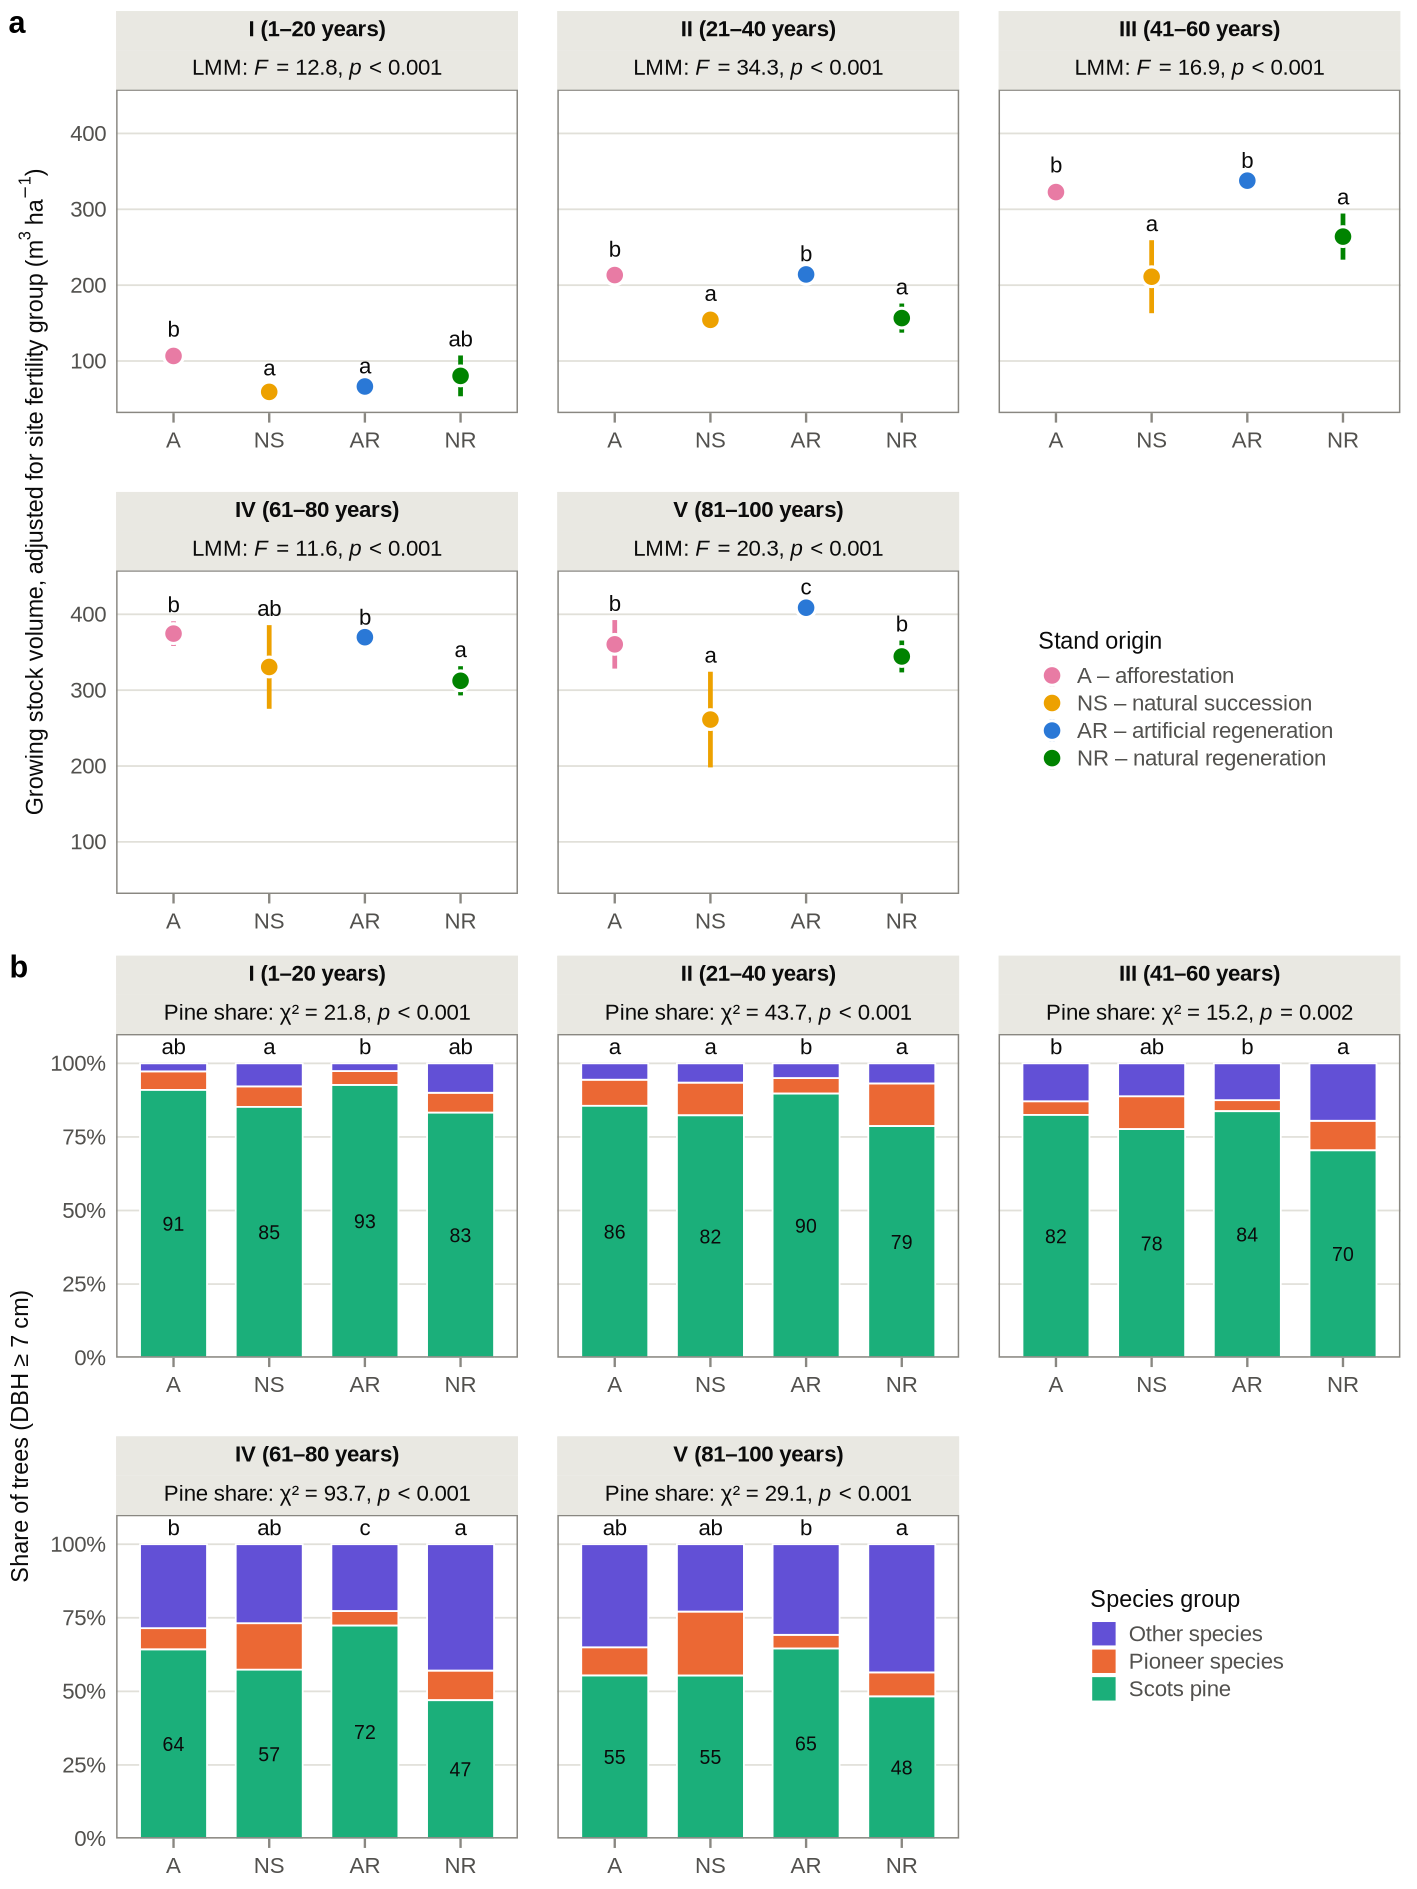

In [26]:
plot_composition <- function(shares, r) {
  d <- shares |> mutate(age_class = as.integer(as.character(age_class)))
  pine <- d |> filter(species_group == "Scots pine") |>
    left_join(r$groups |> mutate(age_class = as.integer(as.character(age_class))), by = c("age_class", "origin"))
  ggplot(d, aes(origin, share)) +
    geom_col(aes(fill = species_group), width = 0.7, colour = "white", linewidth = 0.3) +
    geom_text(data = pine, aes(y = share / 2, label = round(100 * share)),
              size = 7 / .pt, colour = ink, family = font_family) +
    geom_text(data = pine, aes(y = 1, label = group), vjust = -0.6, size = 8 / .pt, colour = ink, family = font_family) +
    age_class_panels(test_result("Pine share", '"χ²"', r$test$chi2, r$test$p, r$test$age_class)) +
    scale_fill_manual(values = species_group_colors, name = "Species group") +
    scale_y_continuous(labels = scales::label_percent(), breaks = seq(0, 1, 0.25), expand = expansion(mult = c(0, 0.1))) +
    labs(x = NULL, y = "Share of trees (DBH ≥ 7 cm)") +
    theme_pub() + legend_in_sixth_panel
}
fig5b <- plot_composition(shares, r_pine)
# cowplot measures text on a null device; the default pdf device does not know the Liberation Sans font
cowplot::set_null_device("agg")
fig5 <- cowplot::plot_grid(fig5a, fig5b, ncol = 1, align = "v", axis = "lr", labels = c("a", "b"),
                           label_fontfamily = font_family, label_size = 11, label_fontface = "bold")
show_figure(fig5, 180, 240, "figure_5.png")

### 5.2 Ordination: PCA, envfit, RDA and PERMDISP

- **Data:** shares in the number of upper-canopy trees (`layer == 1`, DBH ≥ 7 cm) of the 10 most abundant species and of the pooled other species, Hellinger-transformed (square roots of the shares), which reduces the dominance of pine so that the admixture species also affect the result.
- **PCA** (`vegan::rda` without constraints) describes the species composition only. The structural variables (age, growing stock volume, deadwood volume, severity of stand damage and Shannon index) are fitted to the ordination passively (`envfit`, 999 permutations).
- **RDA** with stand origin as the explanatory variable and age as the conditioning variable, and **PERMDISP** (Euclidean distance of the composition profiles to the centroid of the origin type, permutation *F*-test). In both tests the unit is the mean composition profile of a cluster × origin combination (6,325 units), because plots of one cluster are not independent; 999 permutations.

In [27]:
pca <- rda(H)
ev <- eigenvals(pca)
add_table("Table S21", "PCA of Hellinger-transformed species composition: eigenvalues and explained variance.",
          c("Axis", "Eigenvalue", "Explained variance (%)", "Cumulative (%)"),
          cbind(names(ev), fmt(ev, 4), fmt(100 * ev / sum(ev), 1), fmt(100 * cumsum(ev) / sum(ev), 1)),
          note = sprintf(paste("Shares of the number of upper-canopy trees (DBH ≥ 7 cm) of the 10 most abundant species",
                               "and other species on %s plots, Hellinger-transformed."), fmt_n(nrow(H))))

Axis,Eigenvalue,Explained variance (%),Cumulative (%)
PC1,0.0450,39.7,39.7
PC2,0.0218,19.2,58.9
PC3,0.0134,11.8,70.7
PC4,0.0092,8.1,78.9
PC5,0.0062,5.4,84.3
PC6,0.0055,4.9,89.2
PC7,0.0037,3.2,92.4
PC8,0.0030,2.7,95.1
PC9,0.0024,2.1,97.2
PC10,0.0019,1.6,98.8


In [28]:
ef <- envfit(pca, pca_plots[, c("age", "gsv", "deadwood", "damage", "shannon")], permutations = 999, choices = 1:2)
env_labels <- c(age = "Stand age", gsv = "Growing stock volume", deadwood = "Deadwood volume",
                damage = "Severity of stand damage", shannon = "Shannon index (H′)")
add_table("Table S23", "Structural variables fitted to the PCA ordination (envfit).",
          c("Variable", "PC1", "PC2", "r²", "p"),
          cbind(env_labels[rownames(ef$vectors$arrows)], fmt(ef$vectors$arrows[, "PC1"], 3),
                fmt(ef$vectors$arrows[, "PC2"], 3), fmt(ef$vectors$r, 3), fmt_p(ef$vectors$pvals)),
          note = paste("PC1 and PC2 are direction cosines of the fitted vectors; p-values from 999 permutations. The",
                       "variables do not affect the ordination."))

Variable,PC1,PC2,r²,p
Stand age,−0.573,0.819,0.030,0.001
Growing stock volume,−0.867,0.498,0.034,0.001
Deadwood volume,0.949,0.316,0.006,0.001
Severity of stand damage,0.328,0.945,0.000,0.418
Shannon index (H′),0.902,0.431,0.557,0.001


In [29]:
# RDA: stand origin, conditioned on age, on the cluster × origin units
rda_origin <- rda(H_units ~ origin + Condition(age), data = units)
a_rda <- anova(rda_origin, permutations = 999)
# PERMDISP: Euclidean distance of the unit profiles to the centroid of their origin, permutation F test
centroid_profiles <- apply(H_units, 2, function(k) ave(k, units$origin))
distance <- sqrt(rowSums((H_units - centroid_profiles)^2))
F_obs <- anova(lm(distance ~ units$origin))$`F value`[1]
F_perm <- replicate(999, anova(lm(distance ~ sample(units$origin)))$`F value`[1])
p_permdisp <- (sum(F_perm >= F_obs) + 1) / (length(F_perm) + 1)
dispersion <- tapply(distance, units$origin, mean)
n_units <- table(units$origin)

add_table("Table 4",
          paste("Results of redundancy analysis (RDA) and the test of homogeneity of multivariate dispersion",
                "(PERMDISP) of the species composition of *Pinus sylvestris* stands in relation to stand origin."),
          c("Effect", "df", "Variance", "F", "p"),
          rbind(block("RDA", 5),
                c("Stand origin", fmt(a_rda$Df[1], 0), fmt(a_rda$Variance[1], 4), fmt(a_rda$F[1], 1),
                  fmt_p_article(a_rda$`Pr(>F)`[1])),
                c("Residual", fmt_n(a_rda$Df[2]), fmt(a_rda$Variance[2], 4), "–", "–"),
                c("Share of stand origin (%)", "", fmt(100 * rda_origin$CCA$tot.chi / rda_origin$tot.chi, 2), "", ""),
                c("Share of age (%)", "", fmt(100 * rda_origin$pCCA$tot.chi / rda_origin$tot.chi, 2), "", ""),
                inner_header("PERMDISP", "Units", "Distance", "", ""),
                cbind(origins, fmt_n(as.integer(n_units[origins])), fmt(dispersion[origins], 3), "", ""),
                c("Permutation test", "–", "–", fmt(F_obs, 1), fmt_p_article(p_permdisp))),
          note = sprintf(paste("Units of analysis: mean species composition profiles (Hellinger-transformed shares in",
                               "the number of upper-canopy trees) for cluster × origin combinations (n = %s).",
                               "Significance was assessed with permutation tests (999 permutations). RDA with age as a",
                               "conditioning variable; share – the part of the total variation in composition explained",
                               "by stand origin and by age. PERMDISP: distance – mean Euclidean distance of the",
                               "composition profiles from the centroid of the origin type. Full results are given in",
                               "Table S24."), fmt_n(nrow(units))))
add_table("Table S24",
          paste("Differences in species composition between stand origins: redundancy analysis (RDA) and homogeneity",
                "of dispersion (PERMDISP)."),
          c("Term", "df", "Variance", "F", "p"),
          rbind(block("RDA conditioned on stand age", 5),
                cbind(c("Stand origin", "Residual"), fmt(a_rda$Df, 0), fmt(a_rda$Variance, 4), fmt(a_rda$F),
                      fmt_p(a_rda$`Pr(>F)`)),
                pad(rbind(c("Variance explained by stand origin (% of total)",
                            fmt(100 * rda_origin$CCA$tot.chi / rda_origin$tot.chi, 2)),
                          c("Variance explained by stand age (conditioning term, % of total)",
                            fmt(100 * rda_origin$pCCA$tot.chi / rda_origin$tot.chi, 2))), 5),
                block("PERMDISP: distance to the centroid of stand origin", 5),
                pad(inner_header("Stand origin", "Units", "Mean distance"), 5),
                pad(cbind(origins, fmt_n(as.integer(n_units[origins])), fmt(dispersion[origins], 3)), 5),
                c("Permutation test", "", "", fmt(F_obs, 1), fmt_p(p_permdisp))),
          note = paste("Units: mean Hellinger-transformed species profiles of cluster × origin combinations (plots in",
                       "one NFI cluster are not independent). RDA: 999 permutations; PERMDISP: Euclidean distance to",
                       "the group centroid, permutation F test with 999 permutations."))

Table 4. Results of redundancy analysis (RDA) and the test of homogeneity of multivariate dispersion (PERMDISP) of the species composition of *Pinus sylvestris* stands in relation to stand origin.
Effect                     df     Variance  F      p    
RDA                                                     
Stand origin               3      0.0019    39.7   0.001
Residual                   6,320  0.1031    –      –    
Share of stand origin (%)         1.83                  
Share of age (%)                  1.06                  
PERMDISP                   Units  Distance              
A                          630    0.257                 
NS                         373    0.338                 
AR                         4,855  0.229                 
NR                         467    0.425                 
Permutation test           –      –         173.3  0.001
Units of analysis: mean species composition profiles (Hellinger-transformed shares in the number of upper-canopy trees) for cluster × origin combinations (n = 6,325). Significance was assessed with permutation tests (999 permutations). RDA with age as a conditioning variable; share – the part of the total variation in composition explained by stand origin and by age. PERMDISP: distance – mean Euclidean distance of the composition profiles from the centroid of the origin type. Full results are given in Table S24.

Table S24. Differences in species composition between stand origins: redundancy analysis (RDA) and homogeneity of dispersion (PERMDISP).
Term                                                             df     Variance       F      p    
RDA conditioned on stand age                                                                       
Stand origin                                                     3      0.0019         39.72  0.001
Residual                                                         6320   0.1031                     
Variance explained by stand origin (% of total)                  1.83                              
Variance explained by stand age (conditioning term, % of total)  1.06                              
PERMDISP: distance to the centroid of stand origin                                                 
Stand origin                                                     Units  Mean distance              
A                                                                630    0.257                      
NS                                                               373    0.338                      
AR                                                               4,855  0.229                      
NR                                                               467    0.425                      
Permutation test                                                                       173.3  0.001
Units: mean Hellinger-transformed species profiles of cluster × origin combinations (plots in one NFI cluster are not independent). RDA: 999 permutations; PERMDISP: Euclidean distance to the group centroid, permutation F test with 999 permutations.

Table S22. PCA loadings of species and centroids of stand origins on the first two axes.
Species / stand origin      PC1      PC2    
Species loadings                            
*Pinus*                     −0.510   −0.379 
*Betula*                    0.826    −0.452 
*Quercus*                   0.189    0.765  
*Picea*                     0.093    0.151  
*Larix*                     0.039    0.060  
*Fagus*                     0.034    0.100  
*Populus*                   0.052    0.026  
*Alnus*                     0.036    0.020  
*Carpinus*                  0.020    0.051  
*Abies*                     0.012    0.038  
Other species               0.077    0.161  
Centroids of stand origins                  
A                           0.0038   −0.0043
NS                          0.0161   −0.0043
AR                          −0.0021  0.0003 
NR                          0.0169   0.0044 
Loadings are elements of the unit-length eigenvectors. Centroids are mean plot scores in the units of the ordination diagram (vegan, scaling 1).

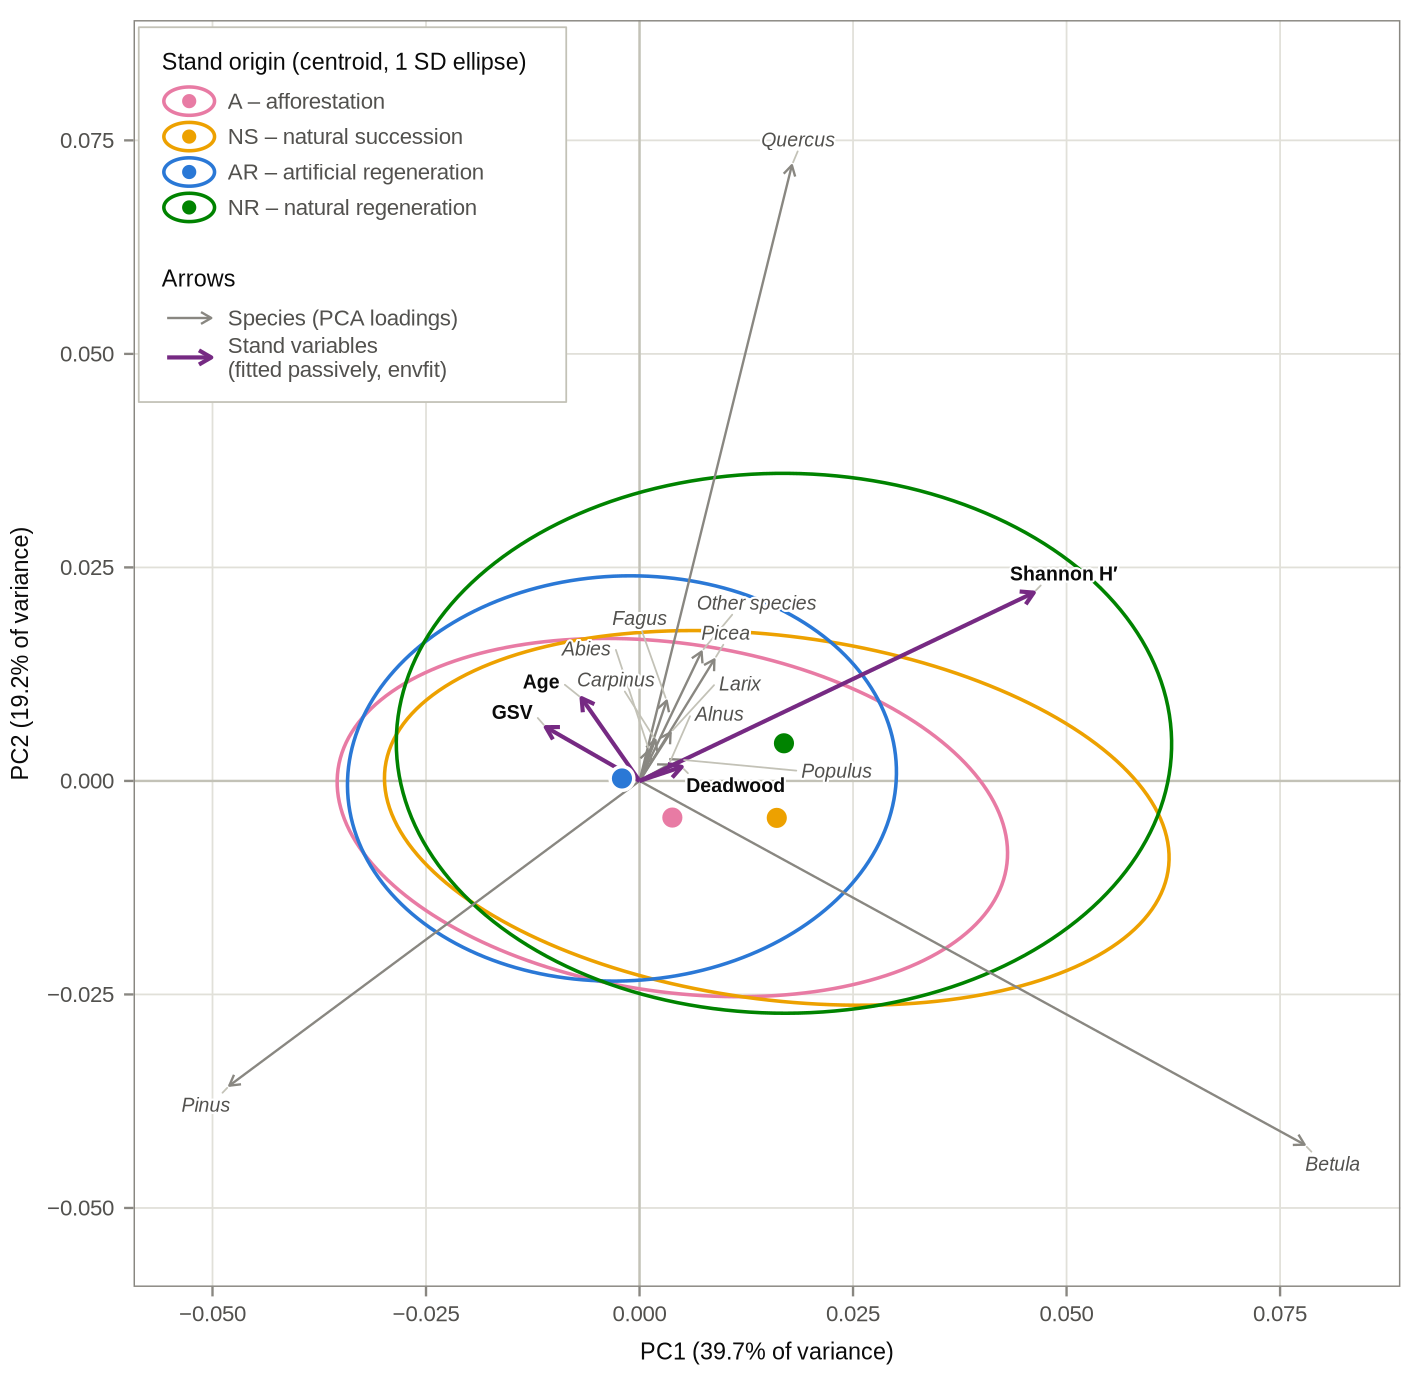

In [30]:
sc <- scores(pca, choices = 1:2, display = "sites", scaling = 1)
sp <- scores(pca, choices = 1:2, display = "species", scaling = 1)
env_names <- c(age = "Age", gsv = "GSV", deadwood = "Deadwood", damage = "Damage", shannon = "Shannon H′")
site_scores <- as_tibble(sc) |> mutate(origin = pca_plots$origin)
centroids <- site_scores |> group_by(origin) |> summarise(PC1 = mean(PC1), PC2 = mean(PC2))
# 1 SD ellipses of the plot scores around the centroids
ellipses <- site_scores |> group_by(origin) |> group_modify(function(g, k) {
  S <- cov(cbind(g$PC1, g$PC2)); e <- eigen(S); t <- seq(0, 2 * pi, length.out = 200)
  xy <- cbind(cos(t), sin(t)) %*% diag(sqrt(e$values)) %*% t(e$vectors)
  tibble(PC1 = xy[, 1] + mean(g$PC1), PC2 = xy[, 2] + mean(g$PC2))
})
extent <- max(abs(c(ellipses$PC1, ellipses$PC2)))
species_scale <- 1.25 * extent / max(abs(sp))
# Gray arrows: species loadings; purple arrows: structural variables fitted passively (envfit), p < 0.05.
# Species and variables have separate scales; their directions matter.
species_color <- "#898781"; env_color <- "#762a83"
arrow_species <- "Species (PCA loadings)"; arrow_env <- "Stand variables\n(fitted passively, envfit)"
species_df <- as_tibble(sp * species_scale, rownames = "code") |> mutate(label = code, type = arrow_species)
env_significant <- names(ef$vectors$pvals)[ef$vectors$pvals < 0.05]
env_df <- as_tibble(scores(ef, display = "vectors")[env_significant, , drop = FALSE] * 1.1 * extent, rownames = "code") |>
  mutate(label = env_names[code], type = arrow_env)
# Labels start just beyond the arrow heads; unlabeled points on the centroids and along the arrows repel the labels
pca_labels <- bind_rows(
  bind_rows(species_df |> mutate(colour = ink2, face = "italic"), env_df |> mutate(colour = ink, face = "bold")) |>
    mutate(len = sqrt(PC1^2 + PC2^2), nx = 0.05 * extent * PC1 / len, ny = 0.05 * extent * PC2 / len, ps = 1),
  centroids |> mutate(ps = 5),
  bind_rows(species_df, env_df) |> rowwise() |>
    reframe(u = seq(0, 1, length.out = max(2, ceiling(sqrt(PC1^2 + PC2^2) / (0.025 * extent)))),
            PC1 = PC1 * u, PC2 = PC2 * u) |> mutate(ps = 1)) |>
  transmute(PC1, PC2, ps, label = coalesce(label, ""), colour = coalesce(colour, ink),
            face = coalesce(face, "plain"), nx = coalesce(nx, 0), ny = coalesce(ny, 0))
# Both axes have the same range and ticks; aspect ratio 1:1
limits <- range(c(ellipses$PC1, ellipses$PC2, species_df$PC1, species_df$PC2)) + c(-0.18, 0.18) * extent
axis_labels <- scales::label_number(accuracy = 0.001, style_negative = "minus")
ellipse_key <- function(data, params, size) {      # legend key of stand origin: an ellipse
  t <- seq(0, 2 * pi, length.out = 90)
  grid::polygonGrob(0.5 + 0.46 * cos(t), 0.5 + 0.40 * sin(t),
                    gp = grid::gpar(col = data$colour, fill = NA, lwd = data$linewidth * .pt))
}
legend_in_corner <- if (packageVersion("ggplot2") >= "3.5.0") {
  theme(legend.position = "inside", legend.position.inside = c(0.015, 0.985))
} else {
  theme(legend.position = c(0.015, 0.985))
}
fig7 <- ggplot() +
  geom_hline(yintercept = 0, colour = axis_color, linewidth = 0.4) +
  geom_vline(xintercept = 0, colour = axis_color, linewidth = 0.4) +
  geom_polygon(data = ellipses, aes(PC1, PC2, colour = origin), fill = NA, linewidth = 0.6, key_glyph = ellipse_key) +
  geom_segment(data = species_df, aes(0, 0, xend = PC1, yend = PC2, linetype = type), colour = species_color,
               linewidth = 0.4, arrow = arrow(length = unit(1.5, "mm"))) +
  geom_segment(data = env_df, aes(0, 0, xend = PC1, yend = PC2, linetype = type), colour = env_color,
               linewidth = 0.7, arrow = arrow(length = unit(1.8, "mm"))) +
  geom_point(data = centroids, aes(PC1, PC2, fill = origin), shape = 21, size = 3.4, colour = "white", stroke = 0.9) +
  geom_text_repel(data = pca_labels, aes(PC1, PC2, label = label, point.size = ps),
                  colour = pca_labels$colour, fontface = pca_labels$face, size = 7 / .pt, family = font_family,
                  nudge_x = pca_labels$nx, nudge_y = pca_labels$ny, bg.colour = "white", bg.r = 0.15,
                  segment.colour = axis_color, segment.size = 0.3, min.segment.length = 0,
                  box.padding = 0.2, point.padding = 0, force_pull = 0.5, max.overlaps = Inf, seed = 1) +
  scale_colour_manual(values = origin_colors, labels = origin_labels, name = "Stand origin (centroid, 1 SD ellipse)",
                      aesthetics = c("colour", "fill")) +
  scale_linetype_manual(values = setNames(c("solid", "solid"), c(arrow_species, arrow_env)),
                        breaks = c(arrow_species, arrow_env), name = "Arrows") +
  scale_x_continuous(breaks = seq(-1, 1, by = 0.025), labels = axis_labels) +
  scale_y_continuous(breaks = seq(-1, 1, by = 0.025), labels = axis_labels) +
  labs(x = sprintf("PC1 (%.1f%% of variance)", 100 * ev[1] / sum(ev)),
       y = sprintf("PC2 (%.1f%% of variance)", 100 * ev[2] / sum(ev))) +
  coord_equal(xlim = limits, ylim = limits, expand = FALSE) +
  theme_pub() +
  theme(panel.grid.major.x = element_line(colour = grid_color, linewidth = 0.3),
        axis.ticks.y = element_line(colour = frame_color, linewidth = 0.4), axis.ticks.length.y = unit(1.2, "mm"),
        legend.justification = c(0, 1), legend.box = "vertical", legend.box.just = "left",
        legend.background = element_rect(fill = "white", colour = NA),
        legend.box.background = element_rect(fill = "white", colour = axis_color, linewidth = 0.3),
        legend.box.margin = margin(1.5, 2, 1.5, 1.5, "mm"), legend.spacing.y = unit(2.5, "mm"),
        legend.key.width = unit(7, "mm"), legend.key.height = unit(4.5, "mm")) +
  legend_in_corner +
  guides(colour = guide_legend(ncol = 1, order = 1, override.aes = list(size = 2.4)),
         fill = guide_legend(ncol = 1, order = 1),
         linetype = guide_legend(order = 2, override.aes = list(colour = c(species_color, env_color),
                                                                linewidth = c(0.4, 0.7))))
show_figure(fig7, 180, 176, "figure_7.png")

loadings <- pca$CA$v[, 1:2]
species_txt <- ifelse(rownames(loadings) == "Other species", "Other species", paste0("*", rownames(loadings), "*"))
add_table("Table S22", "PCA loadings of species and centroids of stand origins on the first two axes.",
          c("Species / stand origin", "PC1", "PC2"),
          rbind(block("Species loadings", 3), cbind(species_txt, fmt(loadings[, 1], 3), fmt(loadings[, 2], 3)),
                block("Centroids of stand origins", 3),
                cbind(as.character(centroids$origin), fmt(centroids$PC1, 4), fmt(centroids$PC2, 4))),
          note = paste("Loadings are elements of the unit-length eigenvectors. Centroids are mean plot scores in the",
                       "units of the ordination diagram (vegan, scaling 1)."))

## 6. Species diversity: Shannon index within age classes

*Article: Sections 2.3 and 3.4, Fig. 8, Tables S13–S16.*

The same linear mixed model as in Section 4, without the site fertility group, and the linear trend across age classes within origin types (Holm correction for four origins).

In [31]:
m_lmm_sh <- lme(shannon ~ origin * age_class, random = ~ 1 | cluster,
                weights = varIdent(form = ~ 1 | age_class * origin),
                data = plots_100, method = "REML", control = lme_control)
r_sh <- compare_origins(m_lmm_sh)
t_sh <- lmm_tables(c("Table S13", "Table S14", "Table S15"), "the Shannon index (H′)", "", m_lmm_sh, r_sh,
                   plots_100, 3, "Shannon index ~ stand origin × age class.")

Table S13. Linear mixed model of the Shannon index (H′) in age classes: tests of fixed effects and variance components.
Effect                                             F       df1    df2    p      
Fixed effects                                                                   
Stand origin                                       26.84   3      5736   < 0.001
Age class                                          3.68    4      5736   0.005  
Stand origin × age class                           1.00    12     5736   0.450  
Simple effects of stand origin within age classes                               
I (1–20 years)                                     3.16    3      5736   0.024  
II (21–40 years)                                   6.27    3      5736   < 0.001
III (41–60 years)                                  6.98    3      5736   < 0.001
IV (61–80 years)                                   27.38   3      5736   < 0.001
V (81–100 years)                                   12.28   3      5736   < 0.001
Variance components: SD                                                         
Cluster (random intercept)                         0.227                        
Residual SD, age class                             A       NS     AR     NR     
I (1–20 years)                                     0.231   0.290  0.264  0.390  
II (21–40 years)                                   0.325   0.300  0.280  0.305  
III (41–60 years)                                  0.245   0.350  0.241  0.399  
IV (61–80 years)                                   0.295   0.361  0.260  0.358  
V (81–100 years)                                   0.236   0.445  0.239  0.334  
Residual variance structure                                                     
Residual variance                                  AIC                          
Specific to age class                              6682.7                       
Specific to age class × stand origin (used)        6614.6                       
Shannon index ~ stand origin × age class. Random intercept of NFI cluster; residual variance specific to each age class × stand origin combination (nlme::lme, varIdent, REML), supported by AIC. F tests from emmeans::joint_tests.

Age class,Stand origin,Plots,Mean,SE,95% CI,Group
I (1–20 years),A,94,0.237,0.032,0.174 to 0.300,a
I (1–20 years),NS,138,0.310,0.031,0.250 to 0.371,a
I (1–20 years),AR,534,0.239,0.014,0.211 to 0.267,a
I (1–20 years),NR,22,0.451,0.091,0.272 to 0.630,a
II (21–40 years),A,221,0.340,0.026,0.289 to 0.391,a
II (21–40 years),NS,207,0.324,0.026,0.273 to 0.374,a
II (21–40 years),AR,"1,145",0.304,0.010,0.284 to 0.324,a
II (21–40 years),NR,100,0.467,0.037,0.394 to 0.541,b
III (41–60 years),A,273,0.243,0.021,0.202 to 0.283,a
III (41–60 years),NS,35,0.352,0.068,0.219 to 0.486,ab


Age class,Contrast,Difference,SE,df,t,p (Holm)
I (1–20 years),A − NS,−0.073,0.044,5736,−1.67,0.282
I (1–20 years),A − AR,−0.002,0.035,5736,−0.05,0.958
I (1–20 years),A − NR,−0.214,0.097,5736,−2.21,0.134
I (1–20 years),NS − AR,0.071,0.034,5736,2.12,0.136
I (1–20 years),NS − NR,−0.141,0.096,5736,−1.46,0.286
I (1–20 years),AR − NR,−0.212,0.092,5736,−2.30,0.129
II (21–40 years),A − NS,0.016,0.036,5736,0.45,0.952
II (21–40 years),A − AR,0.036,0.028,5736,1.29,0.591
II (21–40 years),A − NR,−0.127,0.045,5736,−2.80,0.021
II (21–40 years),NS − AR,0.020,0.027,5736,0.71,0.952


In [32]:
trend_sh <- contrast(emmeans(m_lmm_sh, ~ age_class | origin), "poly") |> as.data.frame() |>
  filter(contrast == "linear") |> mutate(p_holm = p.adjust(p.value, "holm"))
add_table("Table S16", "Linear trend of the Shannon index (H′) across age classes within stand origins.",
          c("Stand origin", "Estimate", "SE", "df", "t", "p", "p (Holm)"),
          with(trend_sh, cbind(as.character(origin), fmt(estimate, 3), fmt(SE, 3), fmt(df, 0), fmt(t.ratio),
                               fmt_p(p.value), fmt_p(p_holm))),
          note = paste("Linear polynomial contrast of the estimated marginal means over the five age classes",
                       "(coefficients −2, −1, 0, 1, 2), from the model in Table S13; Holm correction for four stand",
                       "origins."))

Stand origin,Estimate,SE,df,t,p,p (Holm)
A,0.196,0.106,5736,1.86,0.063,0.190
NS,0.441,0.288,5736,1.53,0.126,0.252
AR,0.177,0.033,5736,5.35,< 0.001,< 0.001
NR,0.275,0.200,5736,1.37,0.170,0.252


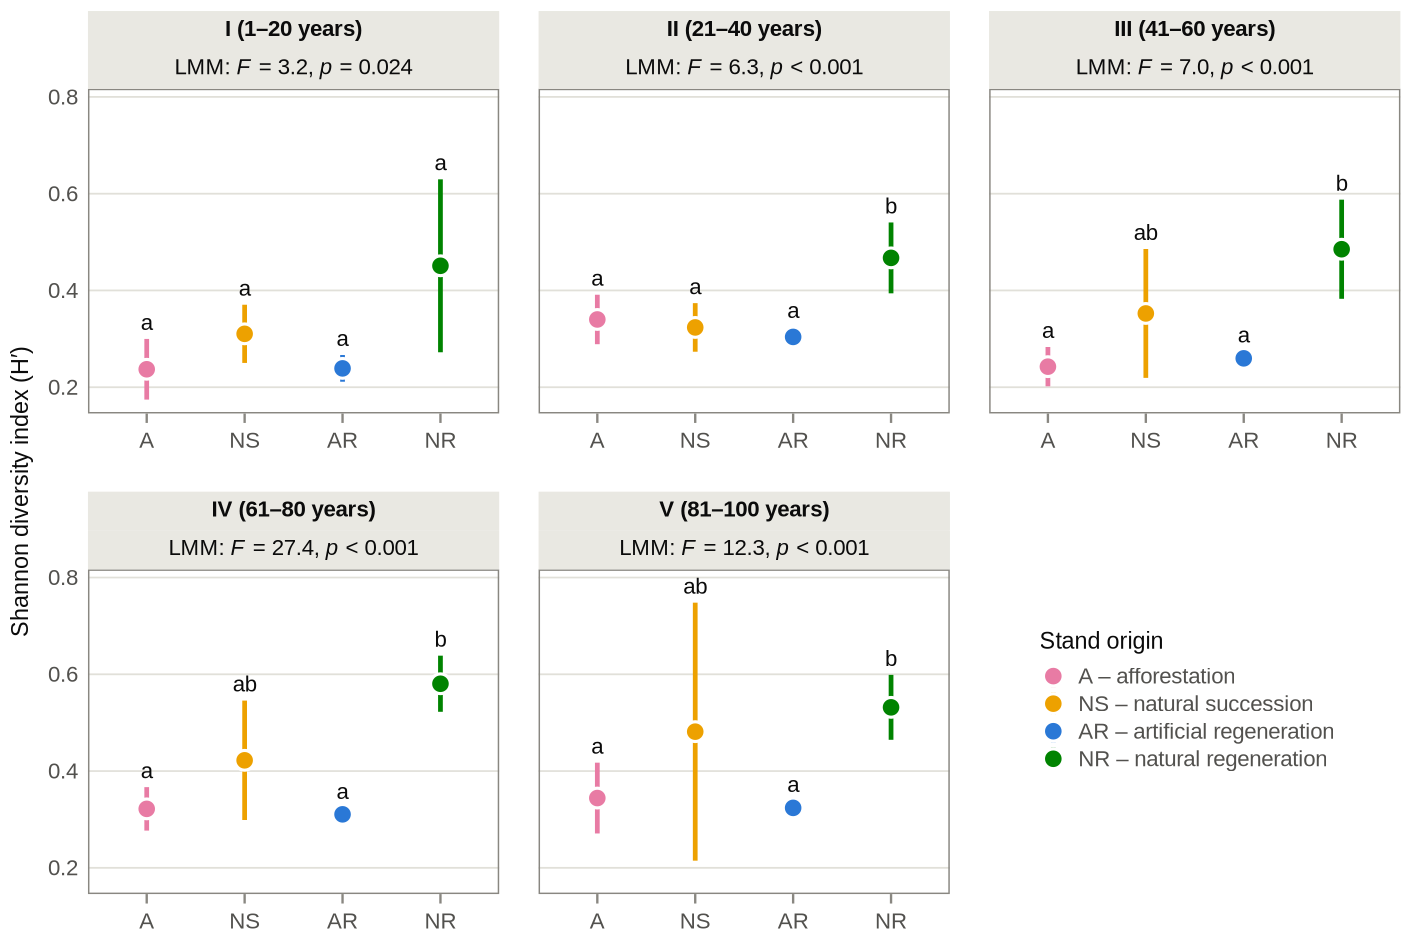

In [33]:
fig8 <- plot_means(r_sh, "Shannon diversity index (H′)")
show_figure(fig8, 180, 120, "figure_8.png")

## 7. Standing dead trees

*Article: Sections 2.3, 2.4 and 3.5, Table 5, Figs. 9–11, Tables S9 and S25–S27.*

### 7.1 Plot-level model

The number of standing dead trees per plot (12,187 plots) has many zeros and a variance several times larger than the mean, so it is modeled with negative binomial regression (`MASS::glm.nb`) with a logarithmic link:

$$\log\big(\mathrm{E}(Y)\big) = \beta_0 + f(\mathrm{age}) + \sum_{i=1}^{k} \beta_i X_i, \qquad \mathrm{Var}(Y) = \mu + \mu^2/\theta,$$

where *f*(age) is a natural cubic spline with 8 degrees of freedom and *X<sub>i</sub>* are the site fertility group, land type, mode of establishment, the interaction between land type and mode of establishment, and the share of *Pinus sylvestris*; exp(*β<sub>i</sub>*) are incidence rate ratios (IRR). Standard errors are robust to the clustering of plots within NFI clusters (`sandwich::vcovCL`), which avoids estimating a random effect for 5,649 clusters. The joint effects of age (8 spline coefficients), site fertility group and the interaction are tested with Wald χ² tests, and single coefficients with *z*-tests. The effect of post-agricultural land within artificially (A vs. AR) and naturally established stands (NS vs. NR), and the effect of artificial establishment on forest land (AR vs. NR) and on post-agricultural land (A vs. NS), are linear combinations of the coefficients. The partial effect of age (Fig. 9) is the multiple of the number of dead trees relative to the mean effect of age in the sample.

In [34]:
dead_summary <- c(share_of_zeros = mean(plots$dead_n == 0), mean = mean(plots$dead_n), variance = var(plots$dead_n))
round(dead_summary, 2)

m_dead <- glm.nb(dead_n ~ ns(age, df = 8) + fertility + establishment * land + pine_share, data = plots)
m_dead_add <- glm.nb(dead_n ~ ns(age, df = 8) + fertility + establishment + land + pine_share, data = plots)
V_dead <- vcovCL(m_dead, cluster = ~ cluster)
ct <- coeftest(m_dead, vcov. = V_dead)
# Joint Wald test of the coefficients whose names match a pattern, with the cluster-robust covariance matrix
wald <- function(pattern) {
  i <- grep(pattern, names(coef(m_dead))); b <- coef(m_dead)[i]
  W <- drop(t(b) %*% solve(V_dead[i, i]) %*% b)
  c(chi2 = round(W, 1), df = length(i), p = signif(pchisq(W, length(i), lower.tail = FALSE), 3))
}
wald_tests <- rbind(age = wald("^ns\\("), fertility = wald("^fertility"), interaction = wald(":"))
# IRR of an effect within a group: linear combination of coefficients with weights L
effect_within <- function(L) {
  b <- coef(m_dead); l <- setNames(numeric(length(b)), names(b)); l[names(L)] <- L
  est <- sum(l * b); se <- sqrt(drop(t(l) %*% V_dead %*% l))
  c(IRR = exp(est), lower = exp(est - 1.96 * se), upper = exp(est + 1.96 * se), z = est / se,
    p = 2 * pnorm(-abs(est / se)))
}
int <- "establishmentartificial:landpost_agricultural"
within_groups <- rbind(
  "A vs. AR" = effect_within(c(landpost_agricultural = 1, setNames(1, int))),
  "NS vs. NR" = effect_within(c(landpost_agricultural = 1)),
  "AR vs. NR" = effect_within(c(establishmentartificial = 1)),
  "A vs. NS" = effect_within(c(establishmentartificial = 1, setNames(1, int))))

nb_row <- function(term, label) {
  c(label, fmt(ct[term, "Estimate"], 3), fmt(ct[term, "Std. Error"], 3), fmt(ct[term, "z value"]),
    fmt_p_article(ct[term, "Pr(>|z|)"]))
}
wald_row <- function(w, label) c(label, "–", "–", paste("χ² =", fmt(w[["chi2"]], 1)), fmt_p_article(w[["p"]]))
group_row <- function(g, label) {
  x <- within_groups[g, ]
  c(label, fmt(x[["IRR"]]), paste0(fmt(x[["lower"]]), "–", fmt(x[["upper"]])), fmt(x[["z"]]), fmt_p_article(x[["p"]]))
}
add_table("Table 5",
          paste("Results of the negative binomial regression model (standard errors robust to the clustering of plots",
                "within NFI clusters) describing the effects of stand age, site fertility, mode of establishment, land",
                "type and their interaction, and the share of *Pinus sylvestris* on the number of standing dead trees",
                "in pine stands."),
          c("Parametric coefficients", "Estimate β", "SE", "z/χ²", "p"),
          rbind(nb_row("(Intercept)", "Intercept"),
                block("Site fertility group", 5),
                nb_row("fertilitypoor", "poor"), nb_row("fertilitymoderately_fertile", "moderately fertile"),
                nb_row("fertilityfertile", "fertile"),
                block("Mode of establishment", 5), nb_row("establishmentartificial", "artificial"),
                block("Land type", 5), nb_row("landpost_agricultural", "post-agricultural land"),
                nb_row("pine_share", "Share of *Pinus sylvestris*"),
                nb_row(int, "artificial × post-agricultural land"),
                block("Joint (Wald) tests", 5),
                wald_row(wald_tests["age", ], "age (spline, 8 df)"),
                wald_row(wald_tests["fertility", ], "site fertility group (3 df)"),
                wald_row(wald_tests["interaction", ], "establishment × land type (1 df)"),
                inner_header("Effects within groups", "IRR", "95% CI", "z", "p"),
                group_row("A vs. AR", "A versus AR"), group_row("NS vs. NR", "NS versus NR"),
                group_row("AR vs. NR", "AR versus NR"), group_row("A vs. NS", "A versus NS")),
          note = sprintf(paste("Model: explained deviance = %s%%; θ = %s; n = %s (%s clusters). Reference categories:",
                               "very poor sites, natural establishment, forest land. Because of the interaction, the",
                               "coefficient for artificial establishment refers to the AR–NR comparison and that for",
                               "post-agricultural land to the NS–NR comparison; the effects within individual groups",
                               "(IRR – incidence rate ratio with 95%% confidence interval, z-test) are given in the last",
                               "part of the table."),
                         fmt(100 * (1 - m_dead$deviance / m_dead$null.deviance), 1), fmt(m_dead$theta, 3),
                         fmt_n(nobs(m_dead)), fmt_n(n_distinct(plots$cluster))))

ct_df <- as.data.frame(unclass(ct)) |> rownames_to_column("t") |> filter(!grepl("^ns\\(", t))
irr_ci <- with(ct_df, ifelse(t == "(Intercept)", "",
                             paste0(fmt(exp(Estimate), 3), " (", fmt(exp(Estimate - 1.96 * `Std. Error`), 3), "–",
                                    fmt(exp(Estimate + 1.96 * `Std. Error`), 3), ")")))
add_table("Table S9",
          paste("Negative binomial GLM of the number of standing dead trees per plot, with the interaction of mode",
                "of establishment and land type."),
          c("Term", "β", "SE", "z", "p", "IRR (95% CI)"),
          rbind(block("Coefficients", 6),
                cbind(term_labels[ct_df$t], fmt(ct_df$Estimate, 3), fmt(ct_df$`Std. Error`, 3), fmt(ct_df$`z value`),
                      fmt_p(ct_df$`Pr(>|z|)`), irr_ci),
                block("Joint Wald tests", 6), pad(inner_header("Term", "χ²", "df", "p"), 6),
                pad(cbind(c("Stand age (natural spline, 8 df)", "Site fertility group",
                            "Mode of establishment × land type"),
                          fmt(wald_tests[, "chi2"], 1), fmt(wald_tests[, "df"], 0), fmt_p(wald_tests[, "p"])), 6),
                block("Effects within groups", 6), pad(inner_header("Contrast", "IRR (95% CI)", "z", "p"), 6),
                pad(cbind(c("Post-agricultural vs. forest land, artificially established stands (A vs. AR)",
                            "Post-agricultural vs. forest land, naturally established stands (NS vs. NR)",
                            "Artificial vs. natural establishment, forest land (AR vs. NR)",
                            "Artificial vs. natural establishment, post-agricultural land (A vs. NS)"),
                          paste0(fmt(within_groups[, "IRR"], 3), " (", fmt(within_groups[, "lower"], 3), "–",
                                 fmt(within_groups[, "upper"], 3), ")"),
                          fmt(within_groups[, "z"]), fmt_p(within_groups[, "p"])), 6),
                block("Model and response", 6),
                pad(rbind(c("θ (SE)", paste0(fmt(m_dead$theta, 3), " (", fmt(m_dead$SE.theta, 3), ")")),
                          c("Deviance explained", fmt(1 - m_dead$deviance / m_dead$null.deviance, 3)),
                          c("AIC without / with the interaction", paste(fmt(AIC(m_dead_add), 1), "/", fmt(AIC(m_dead), 1))),
                          c("Plots", fmt_n(nobs(m_dead))),
                          c("Plots without standing dead trees (%)", fmt(100 * dead_summary[["share_of_zeros"]], 1)),
                          c("Dead trees per plot: mean (variance)",
                            paste0(fmt(dead_summary[["mean"]], 2), " (", fmt(dead_summary[["variance"]], 2), ")"))), 6)),
          note = paste("Log link; stand age modeled with a natural cubic spline (8 df), whose coefficients are tested",
                       "jointly. Standard errors and Wald tests are cluster-robust (NFI clusters; sandwich::vcovCL).",
                       "IRR – incidence rate ratio; Scots pine share per percentage point. Because of the interaction,",
                       "the coefficient of artificial establishment is the AR vs. NR contrast and that of",
                       "post-agricultural land the NS vs. NR contrast; effects for the other groups are linear",
                       "combinations of coefficients (Effects within groups).", reference_note))

share_of_zeros           mean       variance 
          0.65           0.88           4.47

Table 5. Results of the negative binomial regression model (standard errors robust to the clustering of plots within NFI clusters) describing the effects of stand age, site fertility, mode of establishment, land type and their interaction, and the share of *Pinus sylvestris* on the number of standing dead trees in pine stands.
Parametric coefficients              Estimate β  SE         z/χ²        p     
Intercept                            −4.062      0.296      −13.73      <0.001
Site fertility group                                                          
poor                                 0.118       0.054      2.17        0.030 
moderately fertile                   0.222       0.063      3.54        <0.001
fertile                              0.282       0.107      2.62        0.009 
Mode of establishment                                                         
artificial                           −0.263      0.084      −3.12       0.002 
Land type                                                                     
post-agricultural land               −0.420      0.135      −3.11       0.002 
Share of *Pinus sylvestris*          −0.006      0.001      −5.23       <0.001
artificial × post-agricultural land  0.917       0.147      6.25        <0.001
Joint (Wald) tests                                                            
age (spline, 8 df)                   –           –          χ² = 883.4  <0.001
site fertility group (3 df)          –           –          χ² = 14.3   0.003 
establishment × land type (1 df)     –           –          χ² = 39.0   <0.001
Effects within groups                IRR         95% CI     z           p     
A versus AR                          1.64        1.43–1.89  6.91        <0.001
NS versus NR                         0.66        0.50–0.86  −3.11       0.002 
AR versus NR                         0.77        0.65–0.91  −3.12       0.002 
A versus NS                          1.92        1.51–2.45  5.27        <0.001
Model: explained deviance = 10.2%; θ = 0.396; n = 12,187 (5,649 clusters). Reference categories: very poor sites, natural establishment, forest land. Because of the interaction, the coefficient for artificial establishment refers to the AR–NR comparison and that for post-agricultural land to the NS–NR comparison; the effects within individual groups (IRR – incidence rate ratio with 95% confidence interval, z-test) are given in the last part of the table.

Table S9. Negative binomial GLM of the number of standing dead trees per plot, with the interaction of mode of establishment and land type.
Term                                                                           β                    SE     z        p        IRR (95% CI)       
Coefficients                                                                                                                                    
Intercept                                                                      −4.062               0.296  −13.73   < 0.001                     
Site fertility group: poor                                                     0.118                0.054  2.17     0.030    1.126 (1.012–1.252)
Site fertility group: moderately fertile                                       0.222                0.063  3.54     < 0.001  1.248 (1.104–1.411)
Site fertility group: fertile                                                  0.282                0.107  2.62     0.009    1.325 (1.074–1.636)
Mode of establishment: artificial                                              −0.263               0.084  −3.12    0.002    0.769 (0.652–0.907)
Land type: post-agricultural                                                   −0.420               0.135  −3.11    0.002    0.657 (0.504–0.856)
Scots pine share (% of volume)                                                 −0.006               0.001  −5.23    < 0.001  0.994 (0.991–0.996)
Artificial establishment × post-agricultural land                              0.917                0.147  6.25     < 0.001  2.502 (1.876–3.335)
Joint Wald tests                                                                                                                                
Term                                                                           χ²                   df     p                                    
Stand age (natural spline, 8 df)                                               883.4                8      < 0.001                              
Site fertility group                                                           14.3                 3      0.003                                
Mode of establishment × land type                                              39.0                 1      < 0.001                              
Effects within groups                                                                                                                           
Contrast                                                                       IRR (95% CI)         z      p                                    
Post-agricultural vs. forest land, artificially established stands (A vs. AR)  1.644 (1.428–1.893)  6.91   < 0.001                              
Post-agricultural vs. forest land, naturally established stands (NS vs. NR)    0.657 (0.504–0.856)  −3.11  0.002                                
Artificial vs. natural establishment, forest land (AR vs. NR)                  0.769 (0.652–0.907)  −3.12  0.002                                
Artificial vs. natural establishment, post-agricultural land (A vs. NS)        1.924 (1.509–2.454)  5.27   < 0.001                              
Model and response                                                                                                                              
θ (SE)                                                                         0.396 (0.011)                                                    
Deviance explained                                                             0.102                                                            
AIC without / with the interaction                                             28857.7 / 28817.3                                                
Plots                                                                          12,187                                                           
Plots without standing dead trees (%)                                          65.0       

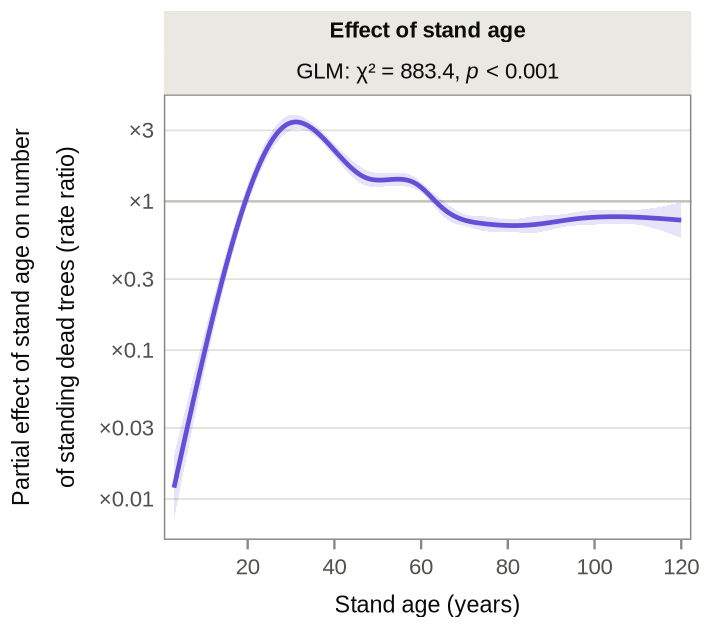

In [35]:
# Partial effect of age: spline part of the linear predictor, centered on its mean in the sample
age_effect <- function(ages) {
  grid <- plots[rep(1, length(ages)), ]; grid$age <- ages
  X <- model.matrix(delete.response(terms(m_dead)), grid, xlev = m_dead$xlevels)
  i <- grep("^ns\\(", colnames(X))
  Xc <- sweep(X[, i, drop = FALSE], 2, colMeans(model.matrix(m_dead)[, i]))
  tibble(age = ages, effect = drop(Xc %*% coef(m_dead)[i]), se = sqrt(rowSums((Xc %*% V_dead[i, i]) * Xc)))
}
age_grid <- age_effect(seq(min(plots$age), max(plots$age), length.out = 200))
fig9 <- ggplot(age_grid |> mutate(fit = exp(effect), lower = exp(effect - 1.96 * se), upper = exp(effect + 1.96 * se)),
               aes(age, fit)) +
  geom_hline(yintercept = 1, colour = axis_color, linewidth = 0.4) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = model_color, alpha = 0.15) +
  geom_line(colour = model_color, linewidth = 0.8) +
  scale_x_continuous(breaks = seq(0, 120, 20), expand = expansion(mult = 0.02)) +
  scale_y_log10(breaks = c(0.01, 0.03, 0.1, 0.3, 1, 3), labels = function(x) paste0("×", x)) +
  plot_header("Effect of stand age", test_result("GLM", '"χ²"', wald_tests["age", "chi2"], wald_tests["age", "p"])) +
  labs(x = "Stand age (years)",
       y = expression(atop("Partial effect of stand age on number", "of standing dead trees (rate ratio)"))) +
  theme_pub()
show_figure(fig9, 90, 80, "figure_9.png")

### 7.2 Comparisons within age classes

Number and volume of standing dead trees on the plots up to 100 years old, per hectare (plot values × 25). The 95% confidence intervals of the means come from a bootstrap of whole NFI clusters (999 resamples in each origin × age class cell). The differences among origins are tested with GLMs with a logarithmic link, `y ~ origin × age class`, fitted to the plot values: negative binomial for the number and quasi-Poisson for the volume (non-negative values with many zeros), with cluster-robust standard errors, Wald χ² tests of origin within each age class and pairwise comparisons of the ratios of means with the Holm correction (as in Section 5.1). The models contain only the origin × age class cells, so their means equal the observed means.

In [36]:
# Mean with a 95% CI from a bootstrap of whole clusters
boot_mean <- function(x, clusters, B = 999) {
  clusters <- droplevels(factor(clusters))
  sums <- tapply(x, clusters, sum); counts <- tapply(x, clusters, length)
  draws <- replicate(B, { i <- sample(seq_along(sums), replace = TRUE); sum(sums[i]) / sum(counts[i]) })
  c(estimate = mean(x), lower = unname(quantile(draws, 0.025)), upper = unname(quantile(draws, 0.975)))
}
dead_by_class <- plots_100 |> group_by(age_class, origin) |>
  group_modify(~ bind_rows(
    tibble(variable = "n", !!!boot_mean(.x$dead_n * 25, .x$cluster)),
    tibble(variable = "vol", !!!boot_mean(.x$dead_vol * 25, .x$cluster)))) |>
  ungroup()

r_dead_n <- compare_origins_glm(glm.nb(dead_n ~ origin * age_class, data = plots_100))
r_dead_vol <- compare_origins_glm(glm(dead_vol ~ origin * age_class, family = quasipoisson, data = plots_100))

dead_wide <- dead_by_class |> pivot_wider(names_from = variable, values_from = c(estimate, lower, upper)) |>
  left_join(count(plots_100, age_class, origin), by = c("age_class", "origin")) |>
  left_join(rename(r_dead_n$groups, group_n = group), by = c("age_class", "origin")) |>
  left_join(rename(r_dead_vol$groups, group_vol = group), by = c("age_class", "origin")) |>
  arrange(age_class, origin)
add_table("Table S25",
          "Standing dead trees per hectare by stand origin and age class: means with 95% confidence intervals.",
          c("Age class", "Stand origin", "Plots", "Number (trees ha⁻¹)", "Group", "Volume (m³ ha⁻¹)", "Group"),
          with(dead_wide, cbind(class_label(age_class), as.character(origin), fmt_n(n),
                                paste0(fmt(estimate_n, 1), " (", fmt(lower_n, 1), "–", fmt(upper_n, 1), ")"), group_n,
                                paste0(fmt(estimate_vol, 2), " (", fmt(lower_vol, 2), "–", fmt(upper_vol, 2), ")"),
                                group_vol)),
          note = paste("Plot values (400 m²) multiplied by 25. 95% confidence intervals from 999 bootstrap resamples",
                       "of NFI clusters. Means sharing a letter within an age class do not differ (pairwise comparisons",
                       "with the Holm correction, α = 0.05, Table S27); a – lowest mean."))
add_table("Table S26", "Tests of differences in standing dead trees between stand origins.",
          c("Effect", "χ²", "df", "p"),
          rbind(glm_tests(r_dead_n, "Number of trees: negative binomial GLM"),
                glm_tests(r_dead_vol, "Volume: quasi-Poisson GLM")),
          note = paste("Models: response ~ stand origin × age class with log link, stands up to 100 years old. The",
                       "models contain only origin × age class cells, so their means equal the means in Table S25.",
                       glm_note))
add_table("Table S27", "Pairwise comparisons of stand origins within age classes: standing dead trees.",
          c("Age class", "Contrast", "Ratio", "SE", "z", "p (Holm)"),
          rbind(glm_pairs(r_dead_n, "Number of trees"), glm_pairs(r_dead_vol, "Volume")),
          note = paste("Ratios of means from the models in Table S26; Holm correction for six comparisons within each",
                       "age class.", glm_note))

Age class,Stand origin,Plots,Number (trees ha⁻¹),Group,Volume (m³ ha⁻¹),Group
I (1–20 years),A,94,20.7 (11.5–31.7),b,0.39 (0.16–0.75),b
I (1–20 years),NS,138,7.2 (3.8–11.2),a,0.16 (0.08–0.27),ab
I (1–20 years),AR,534,8.7 (6.2–11.2),a,0.54 (0.20–0.96),b
I (1–20 years),NR,22,2.3 (0.0–6.0),a,0.04 (0.00–0.10),a
II (21–40 years),A,221,79.8 (63.7–98.8),c,3.22 (2.48–4.09),c
II (21–40 years),NS,207,30.4 (22.9–39.1),a,1.17 (0.76–1.66),a
II (21–40 years),AR,"1,145",47.4 (41.6–53.6),b,2.07 (1.78–2.34),b
II (21–40 years),NR,100,19.0 (11.4–28.9),a,0.71 (0.40–1.10),a
III (41–60 years),A,273,41.9 (33.4–51.2),b,6.05 (4.85–7.36),b
III (41–60 years),NS,35,27.1 (15.4–39.7),ab,3.94 (1.15–8.22),ab


Table S26. Tests of differences in standing dead trees between stand origins.
Effect                                       χ²     df  p      
Number of trees: negative binomial GLM                         
Stand origin                                 45.3   3   < 0.001
Age class                                    79.4   4   < 0.001
Stand origin × age class                     74.1   12  < 0.001
Stand origin in age class I (1–20 years)     15.7   3   0.001  
Stand origin in age class II (21–40 years)   46.3   3   < 0.001
Stand origin in age class III (41–60 years)  18.3   3   < 0.001
Stand origin in age class IV (61–80 years)   48.9   3   < 0.001
Stand origin in age class V (81–100 years)   18.0   3   < 0.001
Volume: quasi-Poisson GLM                                      
Stand origin                                 24.6   3   < 0.001
Age class                                    185.6  4   < 0.001
Stand origin × age class                     44.8   12  < 0.001
Stand origin in age class I (1–20 years)     14.1   3   0.003  
Stand origin in age class II (21–40 years)   36.4   3   < 0.001
Stand origin in age class III (41–60 years)  29.5   3   < 0.001
Stand origin in age class IV (61–80 years)   15.7   3   0.001  
Stand origin in age class V (81–100 years)   3.1    3   0.382  
Models: response ~ stand origin × age class with log link, stands up to 100 years old. The models contain only origin × age class cells, so their means equal the means in Table S25. Wald tests with cluster-robust covariance matrix (NFI clusters; sandwich::vcovCL).

Table S27. Pairwise comparisons of stand origins within age classes: standing dead trees.
Age class          Contrast  Ratio   SE      z      p (Holm)
Number of trees                                             
I (1–20 years)     A / NS    2.863   1.029   2.93   0.014   
I (1–20 years)     A / AR    2.382   0.687   3.01   0.013   
I (1–20 years)     A / NR    9.128   6.591   3.06   0.013   
I (1–20 years)     NS / AR   0.832   0.247   −0.62  0.536   
I (1–20 years)     NS / NR   3.188   2.311   1.60   0.219   
I (1–20 years)     AR / NR   3.831   2.653   1.94   0.157   
II (21–40 years)   A / NS    2.620   0.469   5.38   < 0.001 
II (21–40 years)   A / AR    1.682   0.212   4.13   < 0.001 
II (21–40 years)   A / NR    4.197   1.128   5.34   < 0.001 
II (21–40 years)   NS / AR   0.642   0.100   −2.85  0.009   
II (21–40 years)   NS / NR   1.602   0.455   1.66   0.097   
II (21–40 years)   AR / NR   2.496   0.632   3.61   < 0.001 
III (41–60 years)  A / NS    1.545   0.393   1.71   0.434   
III (41–60 years)  A / AR    1.634   0.193   4.15   < 0.001 
III (41–60 years)  A / NR    1.201   0.303   0.72   1.000   
III (41–60 years)  NS / AR   1.057   0.248   0.24   1.000   
III (41–60 years)  NS / NR   0.777   0.251   −0.78  1.000   
III (41–60 years)  AR / NR   0.735   0.171   −1.33  0.739   
IV (61–80 years)   A / NS    0.596   0.135   −2.28  0.067   
IV (61–80 years)   A / AR    1.495   0.214   2.82   0.020   
IV (61–80 years)   A / NR    0.833   0.148   −1.03  0.305   
IV (61–80 years)   NS / AR   2.508   0.464   4.97   < 0.001 
IV (61–80 years)   NS / NR   1.398   0.297   1.58   0.230   
IV (61–80 years)   AR / NR   0.557   0.067   −4.84  < 0.001 
V (81–100 years)   A / NS    0.926   0.372   −0.19  1.000   
V (81–100 years)   A / AR    1.734   0.416   2.30   0.108   
V (81–100 years)   A / NR    1.013   0.262   0.05   1.000   
V (81–100 years)   NS / AR   1.872   0.620   1.89   0.234   
V (81–100 years)   NS / NR   1.094   0.388   0.25   1.000   
V (81–100 years)   AR / NR   0.584   0.088   −3.56  0.002   
Volume                                                      
I (1–20 years)     A / NS    2.404   1.241   1.70   0.179   
I (1–20 years)     A / AR    0.728   0.406   −0.57  0.569   
I (1–20 years)     A / NR    10.554  8.679   2.87   0.021   
I (1–20 years)     NS / AR   0.303   0.151   −2.39  0.067   
I (1–20 years)     NS / NR   4.390   3.440   1.89   0.177   
I (1–20 years)     AR / NR   14.495  11.764  3.29   0.006   
II (21–40 years)   A / NS    2.742   0.630   4.39   < 0.001 
II (21–40 years)   A / AR    1.556   0.225   3.06   0.007   
II (21–40 years)   A / NR    4.559   1.385   5.00   < 0.001 
II (21–40 years)   NS / AR   0.568   0.117   −2.74  0.012   
II (21–40 years)   NS / NR   1.663   0.562   1.50   0.133   
II (21–40 years)   AR / NR   2.929   0.839   3.75   < 0.001 
III (41–60 years)  A / NS    1.535   0.749   0.88   1.000   
III (41–60 years)  A / AR    1.919   0.231   5.42   < 0.001 
III (41–60 years)  A / NR    1.855   0.480   2.39   0.085   
III (41–60 years)  NS / AR   1.250   0.598   0.47   1.000   
III (41–60 years)  NS / NR   1.209   0.645   0.36   1.000   
III (41–60 years)  AR / NR   0.967   0.230   −0.14  1.000   
IV (61–80 years)   A / NS    0.625   0.209   −1.40  0.471   
IV (61–80 years)   A / AR    1.551   0.233   2.92   0.021   
IV (61–80 years)   A / NR    1.408   0.340   1.42   0.471   
IV (61–80 years)   NS / AR   2.481   0.773   2.92   0.021   
IV (61–80 years)   NS / NR   2.252   0.819   2.23   0.102   
IV (61–80 years)   AR / NR   0.908   0.189   −0.46  0.643   
V (81–100 years)   A / NS    1.259   0.974   0.30   1.000   
V (81–100 years)   A / AR    1.514   0.483   1.30   1.000   
V (81–100 years)   A / NR    1.107   0.407   0.28   1.000   
V (81–100 years)   NS / AR   1.203   0.866   0.26   1.000   
V (81–100 years)   NS / NR   0.879   0.653   −0.17  1.000   
V (81–100 years)   AR / NR   0.731   0.171   −1.34  1.000   
Ratios of means from the models in Table S26; Holm correction for s

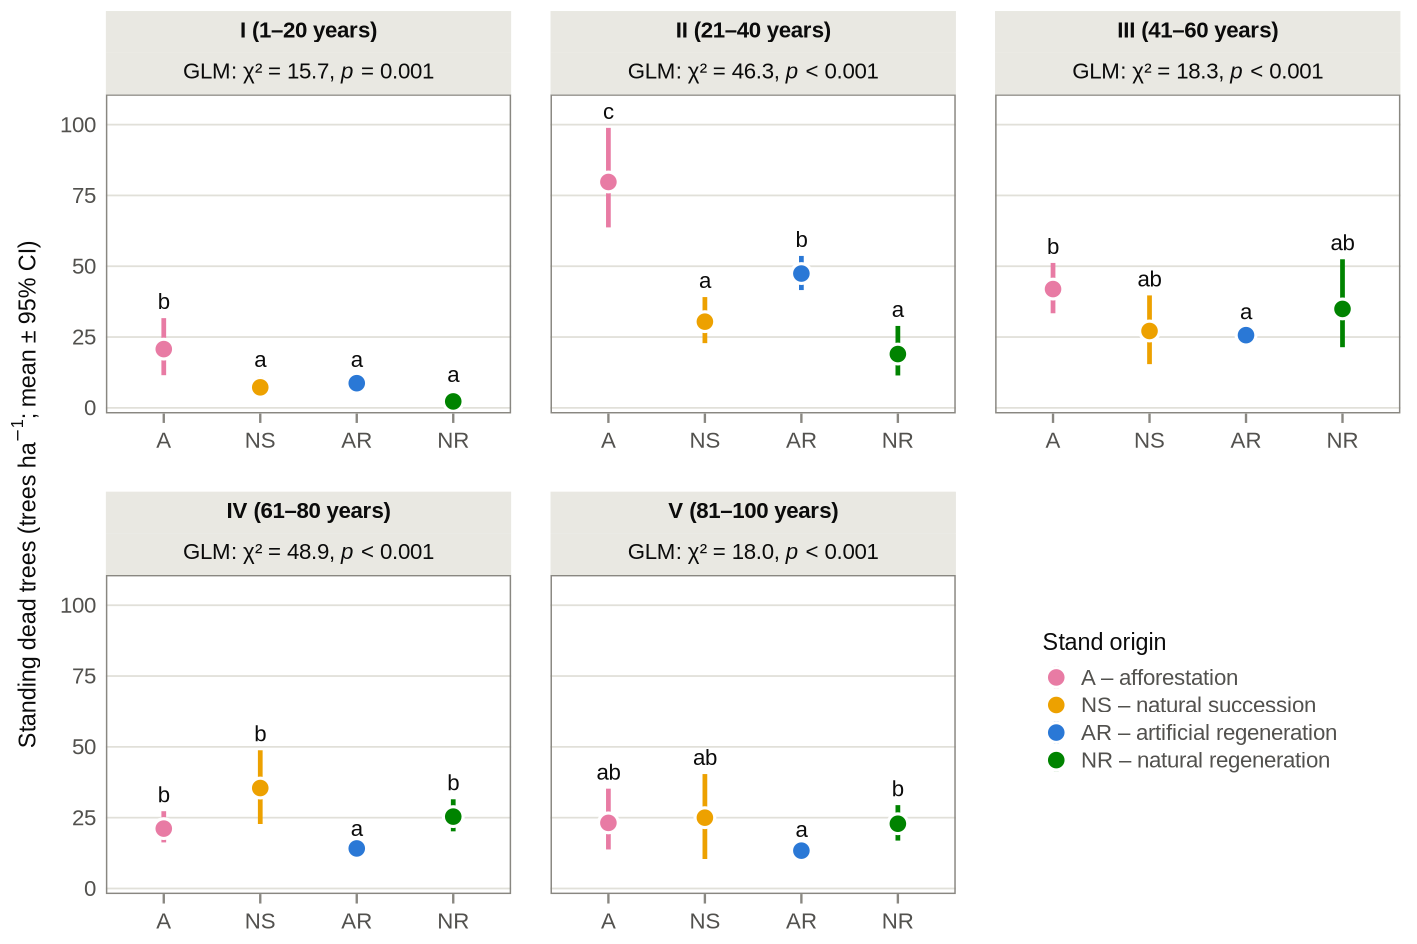

In [37]:
plot_dead <- function(d, r, y_label) {
  d <- d |> left_join(r$groups, by = c("age_class", "origin")) |> mutate(age_class = as.integer(as.character(age_class)))
  ggplot(d, aes(origin, estimate)) +
    geom_linerange(aes(ymin = lower, ymax = upper, colour = origin), linewidth = 0.8) +
    geom_point(aes(fill = origin), shape = 21, size = 2.8, colour = "white", stroke = 0.8) +
    geom_text(aes(y = upper, label = group), vjust = -0.6, size = 8 / .pt, colour = ink, family = font_family) +
    age_class_panels(test_result("GLM", '"χ²"', r$test$chi2, r$test$p, r$test$age_class)) +
    scale_colour_manual(values = origin_colors, labels = origin_labels, name = "Stand origin",
                        aesthetics = c("colour", "fill")) +
    scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0.02, 0.12))) +
    labs(x = NULL, y = y_label) +
    theme_pub() + legend_in_sixth_panel
}
fig10 <- plot_dead(filter(dead_by_class, variable == "n"), r_dead_n,
                   expression("Standing dead trees (trees ha"^-1*"; mean ± 95% CI)"))
show_figure(fig10, 180, 120, "figure_10.png")

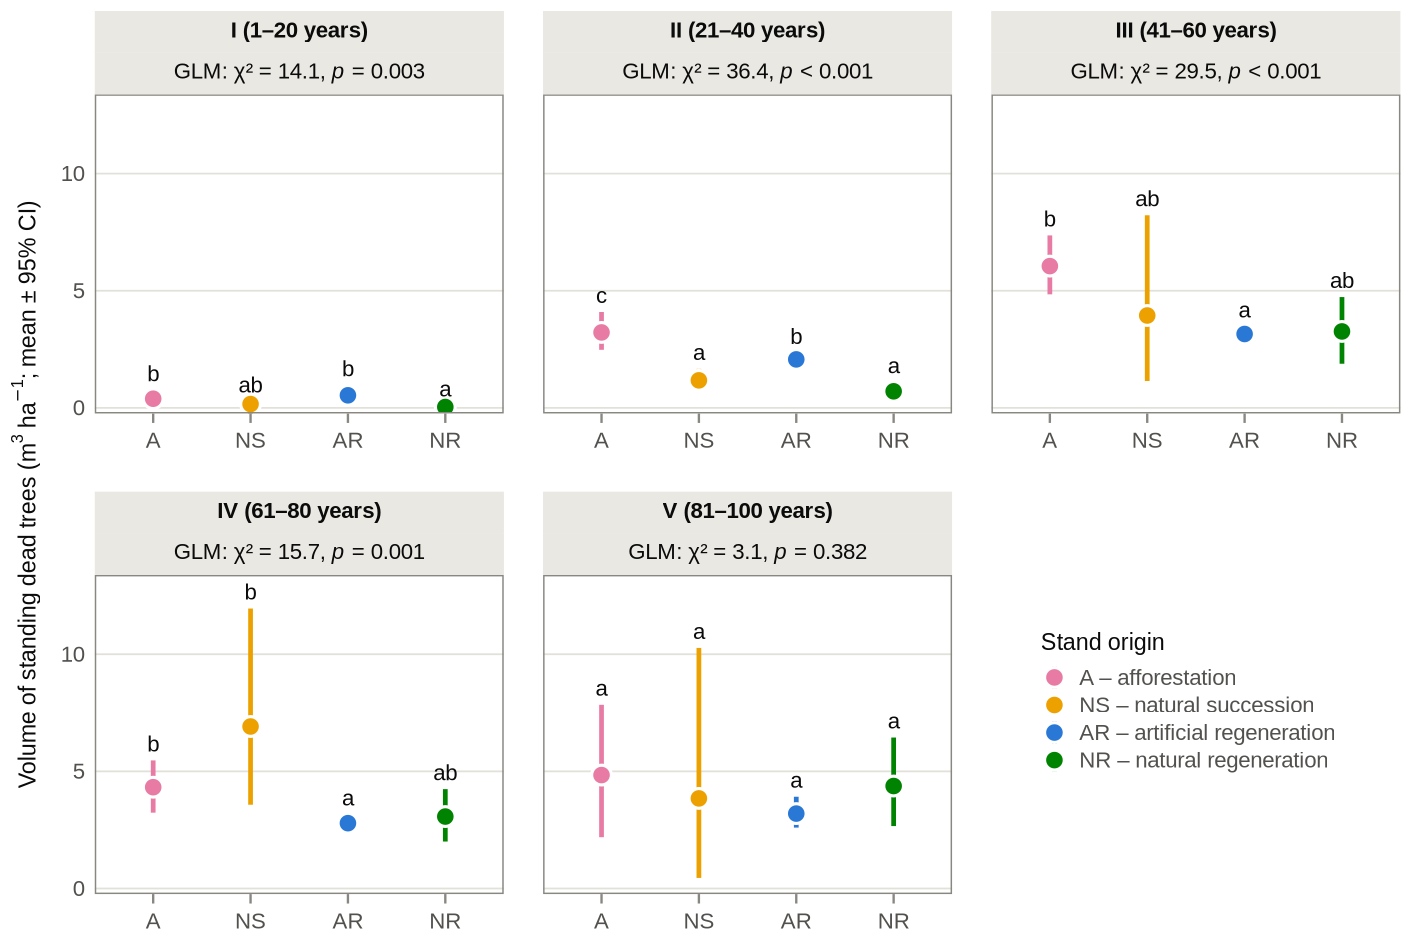

In [38]:
fig11 <- plot_dead(filter(dead_by_class, variable == "vol"), r_dead_vol,
                   expression("Volume of standing dead trees (m"^3*" ha"^-1*"; mean ± 95% CI)"))
show_figure(fig11, 180, 120, "figure_11.png")

## 8. Software

R and package versions used for the results above (Section 2.6 of the article). With `save_outputs <- TRUE`, all tables are also written to `output/tables/all_tables.json`.

In [39]:
article_versions <- c(R = "4.3.1", mgcv = "1.9-0", gamm4 = "0.2-6", nlme = "3.1-163", emmeans = "1.10.0",
                      MASS = "7.3-60", sandwich = "3.1-0", car = "3.1-2", multcomp = "1.4-25", vegan = "2.6-4",
                      ggplot2 = "4.0.3")
packages <- c("mgcv", "gamm4", "lme4", "nlme", "emmeans", "MASS", "sandwich", "lmtest", "car", "multcomp", "vegan",
              "ggplot2", "ggrepel", "cowplot", "ragg", "dplyr", "tidyr", "readr")
versions <- tibble(Software = c("R", packages),
                   Version = c(paste(R.version$major, R.version$minor, sep = "."),
                               sapply(packages, \(p) packageDescription(p)$Version))) |>
  mutate(Article = coalesce(article_versions[Software], ""), Match = ifelse(Article == "", "", Article == Version))
if (save_outputs) {
  jsonlite::write_json(unname(tables_out), file.path(output_dir, "tables", "all_tables.json"),
                       auto_unbox = TRUE, pretty = TRUE)
}
cat(R.version$platform, "|", R.version.string, "\n")
versions

x86_64-conda-linux-gnu | R version 4.3.1 (2023-06-16) 


Software,Version,Article,Match
<chr>,<chr>,<chr>,<chr>
R,4.3.1,4.3.1,TRUE
mgcv,1.9-0,1.9-0,TRUE
gamm4,0.2-6,0.2-6,TRUE
lme4,2.0-6,,
nlme,3.1-163,3.1-163,TRUE
emmeans,1.10.0,1.10.0,TRUE
MASS,7.3-60,7.3-60,TRUE
sandwich,3.1-0,3.1-0,TRUE
lmtest,0.9-40,,
